# Proyecto final PLN · Análisis de sentimiento en reseñas de Mercado Libre (MeLiSA)
**Materia:** Procesamiento de Lenguaje Natural · Universidad Ean
**Docente:** Gerson José Moreno Morales
**Equipo:** Pedro García Romero (Especialista en Machine Learning) · Carlos Trilleras (Magíster en Ciencia de Datos) · Fabiola Aldana Mora (Magíster en Gerencia de IA)

## Pregunta del proyecto
¿Un **Transformer preentrenado en español (BETO)** o un **modelo secuencial (RNN, LSTM o GRU)** justifica su mayor costo frente a una
línea base de **TF-IDF + Regresión Logística / SVM** para clasificar el **sentimiento** (negativo, neutro, positivo) de los comentarios
de compradores de Mercado Libre?

## Tipo de problema: *many-to-one*
- **Entrada (many):** una secuencia de palabras o subpalabras → `"no", "me", "llegó", "completo", ...`
- **Salida (one):** una sola etiqueta para todo el comentario → `negativo`.

En la RNN/LSTM/GRU el último estado oculto emite la predicción; en BETO lo hace la representación del token especial `[CLS]`,
que mediante *self-attention* ya "vio" todo el comentario en ambos sentidos.

## Hoja de ruta del notebook
| Sección | Contenido | Sesión del curso |
|---|---|---|
| 0 | Formulación: usuario, decisión, KPI y error crítico | 1 |
| 1–2 | Auditoría, PII, fuga, limpieza y partición 70/15/15 | 1–2 |
| 3 | Línea base TF-IDF + Regresión Logística / SVM | 1–2 |
| 4–5 | RNN, LSTM y GRU *many-to-one*, criterio de la sesión 3 y variabilidad entre semillas | 3 |
| 6 | Atención, tokenizador, *fine-tuning* de BETO, calibración, abstención, eficiencia, interpretabilidad | **4** |
| 7 | Control de fuera de dominio, robustez y contrafactuales | 3–4 |
| 8 | Sesgo de longitud, revisión manual de errores y resumen agregado de opinión | 3–4 |
| 9–10 | Criterio de adopción de la sesión 4 y demostración del flujo completo | 4 |
| 11 | Conclusiones por rol y declaración de uso de IA | — |

# 0. Formulación del problema
| Elemento | Definición |
|---|---|
| **Usuario** | Analista de experiencia del comprador (equipo de Atención al Cliente / Reputación de vendedores). |
| **Decisión apoyada** | Qué comentarios se atienden primero (cola de prioridad) y a qué vendedor se le envía una alerta temprana. |
| **Situación actual** *(supuestos ilustrativos)* | Un millón de comentarios al mes en un país mediano, 40% negativos. Hoy se lee una muestra del 10% (unos 100.000 comentarios, ~US$13.300 al mes de trabajo de agentes); nueve de cada diez quejas nunca se leen. Las estrellas solo existen en reseñas, no en chats ni reclamos. |
| **Entrada / unidad** | Un comentario de texto libre en español (unidad = comentario). Frecuencia: flujo continuo, procesado en lotes cada hora. |
| **Salida** | Etiqueta (negativo / neutro / positivo) + probabilidad + decisión: *automática* o *revisión humana* (abstención). |
| **Hipótesis de valor** | Si detectamos automáticamente los comentarios negativos, reducimos el tiempo de primera respuesta y las devoluciones. |
| **KPI y línea base** | Primera respuesta a negativos: hoy ~72 h (supuesto), meta < 24 h. Alertas confirmadas por un agente: meta ≥ 80%. Reclamos y devoluciones evitados. |
| **Modo de operación** | Lotes horarios. Criterio operativo fijado aquí, antes de entrenar: procesar el volumen de una hora (~1.400 comentarios) en menos de 10 minutos con un solo proceso. |
| **Clase crítica** | **negativo**. Error más costoso: un comentario negativo leído como positivo (se pierde la alerta). |
| **Métrica principal** | F1 macro (las tres clases pesan igual) + recall de negativo + cobertura automática bajo abstención. |

In [1]:
# 0. Entorno, configuración y reproducibilidad
# Dependencias: ver requirements.txt  (pip install -r requirements.txt)
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")
os.environ.setdefault("HF_DATASETS_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("HF_HUB_VERBOSITY", "error")
import re, time, json, random, warnings, platform, gc
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import joblib, psutil
from scipy.optimize import minimize_scalar
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (f1_score, accuracy_score, recall_score, precision_score, log_loss,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
import torch
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import transformers, sklearn
transformers.logging.set_verbosity_error(); transformers.utils.logging.disable_progress_bar()
tf.get_logger().setLevel("ERROR")

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED); torch.manual_seed(SEED)
for d in ["resultados", "resultados/figuras", "modelos"]:
    os.makedirs(d, exist_ok=True)

# Rutas relativas y parámetros configurables por variables de entorno (ver .env.example)
DATA_PATH = os.environ.get("DATA_PATH", "data/data_melisa_comentarios.csv")
if not os.path.exists(DATA_PATH):            # sin la base completa se usa la muestra controlada del repositorio
    DATA_PATH = "data/muestra_melisa_estratificada.csv"
FRACCION = float(os.environ.get("FRACCION", "1.0"))          # 1.0 = toda la base
MAX_EPOCAS_RNN = int(os.environ.get("MAX_EPOCAS_RNN", "10"))
BERT_CHECKPOINT = os.environ.get("BERT_CHECKPOINT", "dccuchile/bert-base-spanish-wwm-cased")   # BETO
N_TRAIN_BERT = int(os.environ.get("N_TRAIN_BERT", "16000"))   # subconjunto de entrenamiento para BETO (CPU)
EPOCAS_BERT = int(os.environ.get("EPOCAS_BERT", "2"))
N_COMUN = int(os.environ.get("N_COMUN", "5000"))             # tamaño de validación y prueba comunes (todos los modelos)
CLASES = ["negativo", "neutro", "positivo"]
id_clase = {c: i for i, c in enumerate(CLASES)}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COLORES = {"negativo": "#E4572E", "neutro": "#94A3B8", "positivo": "#2BB673"}

entorno = {"python": platform.python_version(), "sistema": platform.platform(), "cpu": platform.processor(),
           "nucleos_logicos": psutil.cpu_count(), "ram_gb": round(psutil.virtual_memory().total / 1e9, 1),
           "gpu": torch.cuda.is_available(), "tensorflow": tf.__version__, "torch": torch.__version__,
           "transformers": transformers.__version__, "scikit-learn": sklearn.__version__, "pandas": pd.__version__,
           "semilla": SEED, "datos": DATA_PATH, "fraccion": FRACCION, "n_train_bert": N_TRAIN_BERT, "epocas_bert": EPOCAS_BERT}
print(json.dumps(entorno, indent=1, ensure_ascii=False))
T_INICIO = time.time()

{
 "python": "3.11.9",
 "sistema": "Windows-10-10.0.26200-SP0",
 "cpu": "Intel64 Family 6 Model 186 Stepping 3, GenuineIntel",
 "nucleos_logicos": 12,
 "ram_gb": 16.8,
 "gpu": false,
 "tensorflow": "2.20.0",
 "torch": "2.15.0+cpu",
 "transformers": "5.23.0",
 "scikit-learn": "1.9.1",
 "pandas": "3.1.1",
 "semilla": 42,
 "datos": "data/data_melisa_comentarios.csv",
 "fraccion": 1.0,
 "n_train_bert": 16000,
 "epocas_bert": 2
}


# 1. Auditoría del corpus
Antes de entrenar revisamos: estructura, nulos, duplicados, contradicciones, distribución de clases, longitud, **datos personales (PII)**
y **riesgos de fuga**. El diccionario de datos y la *data card* completa están en `data/README.md`.

In [2]:
df = pd.read_csv(DATA_PATH)
if FRACCION < 1:
    df = df.sample(frac=FRACCION, random_state=SEED)
print(df.shape)
print(df.isna().sum())
display(df.head())

audit = {}
audit["filas"] = len(df)
audit["duplicados_texto"] = int(df.duplicated("review_content").sum())
contradic = df.groupby("review_content")["sentimiento"].nunique()
audit["textos_contradictorios"] = int((contradic > 1).sum())
audit["clases"] = df["sentimiento"].value_counts().to_dict()
audit["estrellas"] = df["review_rate"].value_counts().sort_index().to_dict()
audit["paises"] = df["country"].value_counts().to_dict()
audit["categorias"] = df["category"].value_counts().to_dict()
palabras = df["review_content"].astype(str).str.split().str.len()
audit["palabras_p50"] = float(palabras.quantile(.50))
audit["palabras_p95"] = float(palabras.quantile(.95))
audit["palabras_p99"] = float(palabras.quantile(.99))
# ¿la etiqueta es una función exacta de las estrellas?
audit["regla_etiqueta"] = pd.crosstab(df.review_rate, df.sentimiento).to_dict()
print(json.dumps({k: v for k, v in audit.items() if k != "regla_etiqueta"}, indent=1, ensure_ascii=False))
display(pd.crosstab(df.review_rate, df.sentimiento))

(487368, 7)
id                0
country           0
category          0
review_content    0
review_title      0
review_rate       0
sentimiento       0
dtype: int64


,id,country,category,review_content,review_title,review_rate,sentimiento
0,1,MLM,"Salud, ropa y cuidado personal / Saúde, roupas...","Esta de muy baja calidad, no fue lo esperado.",No fue lo esperado,2,negativo
1,2,MLA,"Salud, ropa y cuidado personal / Saúde, roupas...","Reconozco que fue muy económico, pero su durab...",Malo,2,negativo
2,3,MLA,"Salud, ropa y cuidado personal / Saúde, roupas...",No me fue útil para mí. Diseño muy bueno.,Malo,2,negativo
3,4,MLA,Alimentos y Bebidas / Alimentos e Bebidas,No fue lo estipulado. Solo eso voy aclarar.,no fue lo esperado,1,negativo
4,5,MLA,Tecnología y electrónica / Tecnologia e electr...,No me fue muy útil para lo que necesitaba.,Malo,2,negativo


{
 "filas": 487368,
 "duplicados_texto": 713,
 "textos_contradictorios": 34,
 "clases": {
  "positivo": 194955,
  "negativo": 194926,
  "neutro": 97487
 },
 "estrellas": {
  "1": 97477,
  "2": 97449,
  "3": 97487,
  "4": 97501,
  "5": 97454
 },
 "paises": {
  "MLA": 211715,
  "MLM": 148607,
  "MCO": 46611,
  "MLC": 45674,
  "MLU": 25765,
  "MLV": 5417,
  "MPE": 3579
 },
 "categorias": {
  "Hogar / Casa": 166117,
  "Tecnología y electrónica / Tecnologia e electronica": 146963,
  "Salud, ropa y cuidado personal / Saúde, roupas e cuidado pessoal": 140367,
  "Arte y entretenimiento / Arte e Entretenimiento": 28582,
  "Alimentos y Bebidas / Alimentos e Bebidas": 5339
 },
 "palabras_p50": 30.0,
 "palabras_p95": 75.0,
 "palabras_p99": 118.0
}


sentimiento,negativo,neutro,positivo
review_rate,,,
1,97477,0,0
2,97449,0,0
3,0,97487,0
4,0,0,97501
5,0,0,97454


## 1.1 Datos personales (PII) y contenido sensible
El texto libre puede contener correos, teléfonos, URL o menciones. Se cuentan con expresiones regulares; si aparecen, se **enmascaran**
(`<EMAIL>`, `<TEL>`, `<URL>`) antes de entrenar, de modo que el modelo conserve la señal de "presencia" sin exponer el valor (sesión 2).

In [3]:
PII = {"EMAIL": r"[\w.+-]+@[\w-]+\.[\w.]+",
       "URL": r"(?:https?://|www\.)\S+",
       "TEL": r"(?<!\d)\+?\d[\d\s\-]{7,}\d(?!\d)"}
texto = df["review_content"].astype(str)
audit["pii"] = {k: int(texto.str.contains(p, regex=True).sum()) for k, p in PII.items()}
print("Comentarios con PII detectada:", audit["pii"])
ej = df[texto.str.contains(PII["EMAIL"] + "|" + PII["TEL"], regex=True)].head(3)["review_content"].tolist()
def enmascarar(s):
    for k, p in PII.items():
        s = re.sub(p, f"<{k}>", s)
    return s
for s in ej:
    print("·", enmascarar(s)[:140])

Comentarios con PII detectada: {'EMAIL': 0, 'URL': 25, 'TEL': 194}


· No puedo creer q la tecnología no a avanzado nada. La cámara es lenta al movimiento y la resolución de la patada de igual manera los acercam
· Por el precio no puedes esperar mucho. No dura casi nada la batería después de un mes de uso y obvio ya no tiene garantía. Mejor gastar un p
· Estimados, tal cual como les comenté cuando los recibí eran dos productos diferentes. Y a la hora de colocarlos sólo pude colocar uno sólo q


## 1.2 Decisiones de limpieza
1. **Textos contradictorios** (mismo texto con sentimientos distintos): se eliminan, porque enseñan dos respuestas a la misma pregunta.
2. **Duplicados exactos:** se conserva una sola copia. Si el mismo texto quedara en entrenamiento y en prueba, el modelo "se lo sabría de memoria" (fuga).
3. **PII:** se enmascara en la columna `texto` (la columna original no se modifica).
4. **No se quitan stopwords** como "no", "muy", "pero": cambian el sentimiento.
5. Minúsculas y tokenización se hacen **dentro de cada modelo** (TF-IDF, `TextVectorization`, tokenizador de BETO), nunca a mano.

Filas después de limpiar: 486621


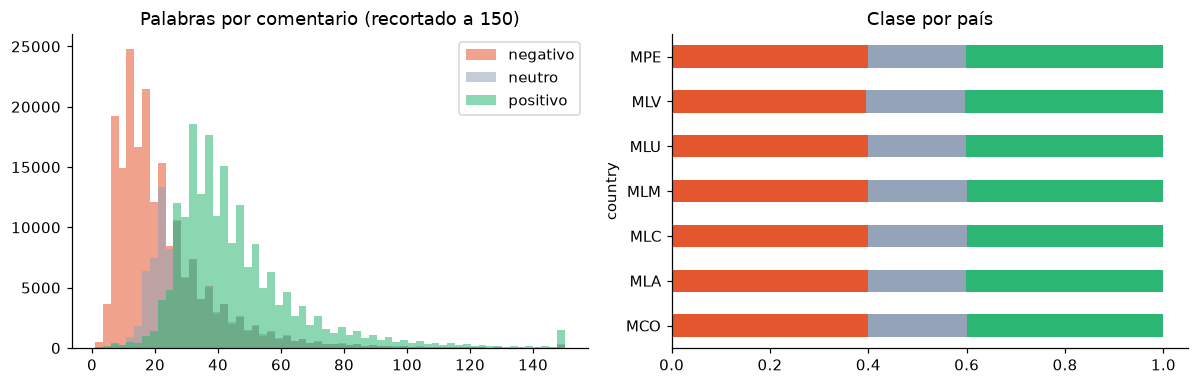

In [4]:
malos = contradic[contradic > 1].index
df = df[~df["review_content"].isin(malos)]
df = df.drop_duplicates("review_content").reset_index(drop=True)
df["texto"] = df["review_content"].astype(str).map(enmascarar)
audit["filas_limpias"] = len(df)
print("Filas después de limpiar:", len(df))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
n_pal = df.texto.str.split().str.len()
for c in CLASES:
    ax[0].hist(n_pal[df.sentimiento == c].clip(upper=150), bins=60, alpha=.55, label=c, color=COLORES[c])
ax[0].set_title("Palabras por comentario (recortado a 150)"); ax[0].legend()
pd.crosstab(df.country, df.sentimiento, normalize="index")[CLASES].plot.barh(stacked=True, ax=ax[1],
    color=[COLORES[c] for c in CLASES], legend=False)
ax[1].set_title("Clase por país"); plt.tight_layout(); plt.savefig("resultados/figuras/eda.png", dpi=150); plt.show()

## 1.3 Prueba de fuga (sobre la base ya limpia): ¿el título delata el sentimiento?
Si un modelo que **solo lee el título** acierta casi tanto como uno que lee el comentario, el título es una pista "regalada":
el comprador lo escribe junto con las estrellas. En producción (chats, preguntas, reclamos) **no existe** título ni estrellas,
así que se excluye. También se excluye `review_rate`, porque es la variable con la que se construyó la etiqueta.

In [5]:
tmp_tr, tmp_te = train_test_split(df, test_size=0.2, stratify=df["sentimiento"], random_state=SEED)
fuga = {}
for col in ["review_title", "review_content"]:
    p = Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=3, sublinear_tf=True)),
                  ("clf", LinearSVC(C=0.5, class_weight="balanced"))])
    p.fit(tmp_tr[col].astype(str), tmp_tr["sentimiento"])
    fuga[col] = f1_score(tmp_te["sentimiento"], p.predict(tmp_te[col].astype(str)), average="macro")
print({k: round(v, 3) for k, v in fuga.items()})
audit["f1_solo_titulo"] = fuga["review_title"]; audit["f1_solo_comentario"] = fuga["review_content"]
del tmp_tr, tmp_te, p; _ = gc.collect()

{'review_title': 0.781, 'review_content': 0.718}


## 1.4 ¿De qué hablan las reseñas?
Al probar la demo con quejas de envío notamos que el modelo no conocía palabras básicas de posventa. Contamos cuántas reseñas mencionan
términos de producto y términos de despacho o atención. Las reseñas de producto de Mercado Libre hablan del producto; el envío y el
vendedor prácticamente no aparecen, lo que indica que ese contenido se filtró en origen. Es un cambio de dominio que hay que tener en
cuenta antes de usar el modelo en chats o reclamos.

In [6]:
# 1.4 Vocabulario de producto frente a vocabulario de posventa
texto_min = df.texto.str.lower()
terminos = ["producto", "calidad", "material", "funciona", "paquete", "devolución", "vendedor", "llegó", "envío", "entrega", "servicio", "atención"]
vocab_pv = pd.DataFrame({"término": terminos,
                         "reseñas que lo mencionan": [int(texto_min.str.contains(rf"\b{t}\b", regex=True).sum()) for t in terminos]})
vocab_pv["% del corpus"] = (100 * vocab_pv["reseñas que lo mencionan"] / len(df)).round(3)
display(vocab_pv)
audit["vocabulario_posventa"] = dict(zip(vocab_pv["término"], vocab_pv["reseñas que lo mencionan"]))

,término,reseñas que lo mencionan,% del corpus
0,producto,120267,24.715
1,calidad,106222,21.828
2,material,27169,5.583
3,funciona,32055,6.587
4,paquete,1724,0.354
5,devolución,1187,0.244
6,vendedor,2,0.000
7,llegó,0,0.000
8,envío,0,0.000
9,entrega,0,0.000


# 2. Partición: entrenamiento 70% · validación 15% · prueba 15%
| Conjunto | Para qué se usa | Analogía de estudio |
|---|---|---|
| **Entrenamiento** | El modelo aprende los pesos (y el vocabulario / IDF). | Los ejercicios resueltos del libro. |
| **Validación** | Elegimos hiperparámetros (C, épocas, *early stopping*, umbral, temperatura) y el modelo campeón. | Los simulacros antes del examen. |
| **Prueba** | Se usa **una sola vez** al final para reportar el desempeño real. | El examen final, que nadie ha visto. |

La partición es **aleatoria y estratificada**: las reseñas son independientes entre sí (no hay conversaciones ni clientes que agrupar)
y el dataset no trae fecha, así que no es posible una partición temporal (limitación documentada en la *data card*).

**Subconjuntos comunes (sesión 4).** BETO en CPU no puede evaluar 73.000 comentarios en un tiempo razonable. Por eso se extraen,
con la misma semilla y de forma estratificada, una **validación común** y una **prueba común** de `N_COMUN` comentarios. **Todos** los
modelos se comparan sobre esos mismos comentarios (comparación justa); los modelos baratos además se reportan sobre la prueba completa.

In [7]:
train, temp = train_test_split(df, test_size=0.30, stratify=df["sentimiento"], random_state=SEED)
val, test = train_test_split(temp, test_size=0.50, stratify=temp["sentimiento"], random_state=SEED)
assert not (set(train.texto) & set(test.texto)) and not (set(train.texto) & set(val.texto))
y_tr, y_va, y_te = train["sentimiento"].values, val["sentimiento"].values, test["sentimiento"].values
n_c = min(N_COMUN, len(val) - 3, len(test) - 3)
idx_vc = np.sort(train_test_split(np.arange(len(val)), train_size=n_c, stratify=y_va, random_state=SEED)[0])
idx_tc = np.sort(train_test_split(np.arange(len(test)), train_size=n_c, stratify=y_te, random_state=SEED)[0])
y_vc, y_tc = y_va[idx_vc], y_te[idx_tc]
particion = pd.DataFrame({n: pd.Series(d).value_counts(normalize=True) for n, d in
                          [("train", y_tr), ("val", y_va), ("test", y_te), ("val_comun", y_vc), ("test_comun", y_tc)]}).round(3)
particion.loc["filas"] = [len(y_tr), len(y_va), len(y_te), len(y_vc), len(y_tc)]
display(particion)
audit["n_train"], audit["n_val"], audit["n_test"], audit["n_comun"] = len(train), len(val), len(test), int(n_c)

,train,val,test,val_comun,test_comun
positivo,0.400,0.400,0.400,0.400,0.400
negativo,0.399,0.399,0.399,0.399,0.399
neutro,0.200,0.200,0.200,0.200,0.200
filas,340634.000,72993.000,72994.000,5000.000,5000.000


In [8]:
def metricas(y_true, y_pred, P=None):
    r = recall_score(y_true, y_pred, labels=CLASES, average=None, zero_division=0)
    f = f1_score(y_true, y_pred, labels=CLASES, average=None, zero_division=0)
    out = {"accuracy": accuracy_score(y_true, y_pred),
           "f1_macro": f1_score(y_true, y_pred, average="macro"),
           **{f"f1_{c}": v for c, v in zip(CLASES, f)},
           **{f"recall_{c}": v for c, v in zip(CLASES, r)}}
    if P is not None:
        out["log_loss"] = log_loss([id_clase[c] for c in y_true], np.clip(P, 1e-7, 1), labels=[0, 1, 2])
    return out

resultados = {}      # métricas por modelo
predicciones = {}    # predicciones en prueba completa
probas = {}          # probabilidades (validación, prueba) completas
predictores = {}     # función textos -> probabilidades (para robustez, latencia y demo)

# 3. Línea base: TF-IDF + Regresión Logística y SVM
- TF-IDF con **palabras y bigramas** (`"no llegó"` se vuelve una sola característica), `min_df=3`, `sublinear_tf=True`.
- El vectorizador se ajusta **solo con entrenamiento** (dentro del `Pipeline`).
- `class_weight="balanced"` porque *neutro* es la mitad de frecuente que las otras clases.
- El valor de **C** se escoge con **validación**.

In [9]:
def tfidf():
    return TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=3, max_df=0.9,
                           sublinear_tf=True, max_features=300_000)

busqueda = []
mejores = {}
for nombre, fabrica, Cs in [
        ("TF-IDF + Regresión Logística", lambda C: LogisticRegression(C=C, max_iter=300, class_weight="balanced"), [0.5, 2, 8]),
        ("TF-IDF + SVM lineal", lambda C: LinearSVC(C=C, class_weight="balanced"), [0.05, 0.2, 1])]:
    mejor = None
    for C in Cs:
        t = time.time()
        p = Pipeline([("tfidf", tfidf()), ("clf", fabrica(C))]).fit(train.texto, y_tr)
        seg = time.time() - t
        f1v = f1_score(y_va, p.predict(val.texto), average="macro")
        busqueda.append({"modelo": nombre, "C": C, "f1_val": f1v, "seg_entreno": seg})
        print(f"{nombre:32s} C={C:<5} F1 val={f1v:.4f}  ({seg:.0f}s)")
        if mejor is None or f1v > mejor[0]:
            mejor = (f1v, C, p, seg)
    mejores[nombre] = mejor
pd.DataFrame(busqueda).to_csv("resultados/busqueda_C.csv", index=False)

TF-IDF + Regresión Logística     C=0.5   F1 val=0.7372  (57s)


TF-IDF + Regresión Logística     C=2     F1 val=0.7313  (109s)


TF-IDF + Regresión Logística     C=8     F1 val=0.7162  (112s)


TF-IDF + SVM lineal              C=0.05  F1 val=0.7215  (44s)


TF-IDF + SVM lineal              C=0.2   F1 val=0.7239  (60s)


TF-IDF + SVM lineal              C=1     F1 val=0.7048  (72s)


In [10]:
def latencia(fn, textos, n=200):
    # p50 y p95 de un comentario a la vez (ms) y throughput en lotes de 32 (comentarios/s)
    fn(textos[:2])
    tiempos = []
    for s in textos[:n]:
        t = time.perf_counter(); fn([s]); tiempos.append((time.perf_counter() - t) * 1000)
    t = time.perf_counter()
    for i in range(0, 320, 32):
        fn(textos[i:i + 32])
    return float(np.percentile(tiempos, 50)), float(np.percentile(tiempos, 95)), 320 / (time.perf_counter() - t)

def predictor_sklearn(p):
    orden = [list(p.named_steps["clf"].classes_).index(c) for c in CLASES]
    if hasattr(p.named_steps["clf"], "predict_proba"):
        return lambda textos: p.predict_proba(list(textos))[:, orden]
    def fn(textos):    # SVM: softmax de la función de decisión (puntaje no calibrado)
        z = p.decision_function(list(textos))[:, orden]; e = np.exp(z - z.max(1, keepdims=True)); return e / e.sum(1, keepdims=True)
    return fn

textos_test = list(test.texto)
for nombre, (f1v, C, p, seg) in mejores.items():
    fn = predictor_sklearn(p); predictores[nombre] = fn
    Pv, Pt = fn(val.texto), fn(test.texto)
    probas[nombre] = (Pv, Pt)
    pred_va, pred_te = np.array(CLASES)[Pv.argmax(1)], np.array(CLASES)[Pt.argmax(1)]
    predicciones[nombre] = pred_te
    p50, p95, thr = latencia(fn, textos_test)
    ruta = f"modelos/{'tfidf_lr' if 'Log' in nombre else 'tfidf_svm'}.joblib"
    joblib.dump(p, ruta, compress=3)
    resultados[nombre] = {"familia": "TF-IDF", "hiperparametro": f"C={C}",
                          "val": metricas(y_va, pred_va), "test": metricas(y_te, pred_te),
                          "seg_entreno": seg, "p50_ms_1": p50, "p95_ms_1": p95, "throughput_32": thr,
                          "n_parametros": int(p.named_steps["clf"].coef_.size), "tamano_mb": os.path.getsize(ruta) / 1e6,
                          "vocabulario": len(p.named_steps["tfidf"].vocabulary_)}
    print(f"{nombre}: F1 val {resultados[nombre]['val']['f1_macro']:.4f} | p95 {p95:.2f} ms | {thr:.0f} coment./s")

TF-IDF + Regresión Logística: F1 val 0.7372 | p95 1.09 ms | 8369 coment./s


TF-IDF + SVM lineal: F1 val 0.7239 | p95 1.14 ms | 12806 coment./s


## 3.1 ¿Qué palabras pesan más? (interpretabilidad de la Regresión Logística)

In [11]:
lr = mejores["TF-IDF + Regresión Logística"][2]
vocab = np.array(lr.named_steps["tfidf"].get_feature_names_out())
coefs = lr.named_steps["clf"].coef_
clases_lr = list(lr.named_steps["clf"].classes_)
top = {}
for c in CLASES:
    w = coefs[clases_lr.index(c)]
    idx = np.argsort(w)[-15:][::-1]
    top[c] = [(vocab[i], float(w[i])) for i in idx]
    print(c, "→", ", ".join(vocab[idx]))
json.dump(top, open("resultados/top_palabras.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)

negativo → no cumple, no, mala, no funciona, malo, pésimo, no sirve, no es, pésima, malísimo, malisimo, no lo, horrible, pesimo, no me
neutro → tres estrellas, pero, doy tres, solo que, excelente pero, sin embargo, embargo, el, recomiendo para, malo pero, aceptable, producto pero, igualmente, lo malo, regular
positivo → excelente, de, para, perfecto, que, la, con, en, perfectamente, muy bueno, buen, super, buena, excelentes, recomendado


# 4. Modelos secuenciales many-to-one: RNN, LSTM y GRU (sesión 3)
**Flujo:** texto → tokens → índices (vocabulario aprendido solo con train) → *padding/truncamiento* a 100 tokens
(cubre ~99% de los comentarios; P95 = 75 palabras) → **Embedding** entrenable (64 dimensiones)
→ capa recurrente (64 unidades, `return_sequences=False` = **many-to-one**) → Dropout → Softmax de 3 clases.

- `0` = PAD (relleno), `1` = OOV (palabra desconocida); `mask_zero=True` hace que la red ignore el relleno.
- Se entrena con **Adam**, entropía cruzada, `class_weight` balanceado y **early stopping** mirando la pérdida de **validación**.

In [12]:
VOCAB, LARGO, EMB, UNIDADES = 30_000, 100, 64, 64
vectorizador = layers.TextVectorization(max_tokens=VOCAB, output_sequence_length=LARGO,
                                        standardize="lower_and_strip_punctuation")
vectorizador.adapt(tf.data.Dataset.from_tensor_slices(train.texto.values).batch(4096))   # solo train
def a_indices(textos):
    return np.concatenate([vectorizador(tf.constant(b)).numpy()
                           for b in np.array_split(np.array(textos), max(1, len(textos) // 20000))])
X_tr, X_va, X_te = a_indices(train.texto.values), a_indices(val.texto.values), a_indices(test.texto.values)
Y_tr = np.array([id_clase[c] for c in y_tr]); Y_va = np.array([id_clase[c] for c in y_va])
pesos = {i: len(Y_tr) / (3 * (Y_tr == i).sum()) for i in range(3)}
oov = (X_va == 1).sum() / (X_va > 0).sum()
print("Ejemplo:", train.texto.values[0][:80]); print("Índices:", X_tr[0][:15])
print("Pesos de clase:", {CLASES[k]: round(v, 2) for k, v in pesos.items()}, "| % OOV en validación:", round(100 * oov, 2))
audit["oov_val"] = float(oov)
json.dump(vectorizador.get_vocabulary(), open("modelos/vocabulario_rnn.json", "w", encoding="utf-8"), ensure_ascii=False)

Ejemplo: Me habían gustado en magenta y me las mandaron un color nada que ver!!!.
Índices: [   18  2456   659    11 13122     5    18    20  1047    14    92    53
     3   142     0]
Pesos de clase: {'negativo': np.float64(0.83), 'neutro': np.float64(1.66), 'positivo': np.float64(0.83)} | % OOV en validación: 1.73


In [13]:
def crear(tipo):
    capa = {"RNN": layers.SimpleRNN, "LSTM": layers.LSTM, "GRU": layers.GRU}[tipo]
    m = keras.Sequential([layers.Input((LARGO,), dtype="int64"),
                          layers.Embedding(VOCAB, EMB, mask_zero=True),
                          capa(UNIDADES),                      # many-to-one: solo el último estado
                          layers.Dropout(0.3),
                          layers.Dense(3, activation="softmax")], name=tipo)
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

def hacer_servidor(modelo):   # texto -> probabilidades, "compilado" como en producción
    f = tf.function(lambda x: modelo(vectorizador(x), training=False))
    return lambda textos: f(tf.constant(list(textos))).numpy()

historias = {}
for tipo in ["RNN", "LSTM", "GRU"]:
    tf.random.set_seed(SEED)
    m = crear(tipo)
    parar = keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)
    t = time.time()
    h = m.fit(X_tr, Y_tr, validation_data=(X_va, Y_va), epochs=MAX_EPOCAS_RNN, batch_size=256,
              class_weight=pesos, callbacks=[parar], verbose=2)
    seg = time.time() - t
    historias[tipo] = h.history
    pv = m.predict(X_va, batch_size=1024, verbose=0); pt = m.predict(X_te, batch_size=1024, verbose=0)
    probas[tipo] = (pv, pt)
    pred_va, pred_te = np.array(CLASES)[pv.argmax(1)], np.array(CLASES)[pt.argmax(1)]
    predicciones[tipo] = pred_te
    fn = hacer_servidor(m); predictores[tipo] = fn
    p50, p95, thr = latencia(fn, textos_test)
    ruta = f"modelos/{tipo.lower()}.keras"; m.save(ruta)
    resultados[tipo] = {"familia": "Secuencial", "hiperparametro": f"épocas={len(h.history['loss'])} (mejor={int(np.argmin(h.history['val_loss']))+1})",
                        "val": metricas(y_va, pred_va), "test": metricas(y_te, pred_te),
                        "seg_entreno": seg, "p50_ms_1": p50, "p95_ms_1": p95, "throughput_32": thr,
                        "n_parametros": int(m.count_params()), "tamano_mb": os.path.getsize(ruta) / 1e6, "vocabulario": VOCAB}
    print(f"{tipo}: F1 val={resultados[tipo]['val']['f1_macro']:.4f}  entrenamiento {seg/60:.1f} min | p95 {p95:.1f} ms")
json.dump(historias, open("resultados/historias.json", "w"))
del X_tr, X_va, X_te; gc.collect()

Epoch 1/10


1331/1331 - 83s - 62ms/step - accuracy: 0.7472 - loss: 0.6201 - val_accuracy: 0.7628 - val_loss: 0.5269


Epoch 2/10


1331/1331 - 81s - 61ms/step - accuracy: 0.7860 - loss: 0.5370 - val_accuracy: 0.7729 - val_loss: 0.5168


Epoch 3/10


1331/1331 - 83s - 62ms/step - accuracy: 0.8222 - loss: 0.4653 - val_accuracy: 0.7739 - val_loss: 0.5662


... (16 outputs left out)

Epoch 4/10


1331/1331 - 177s - 133ms/step - accuracy: 0.8578 - loss: 0.3763 - val_accuracy: 0.7725 - val_loss: 0.5575


GRU: F1 val=0.7649  entrenamiento 11.9 min | p95 6.5 ms


852

# 5. Comparación de la sesión 3 (selección con **validación**, reporte con **prueba** completa)

In [14]:
def tabla_resultados(res):
    return pd.DataFrame([{"modelo": k, "familia": v["familia"], "ajuste": v["hiperparametro"],
                          "F1 macro val": v["val"]["f1_macro"], "F1 macro test": v["test"]["f1_macro"],
                          "accuracy test": v["test"]["accuracy"],
                          "F1 neg": v["test"]["f1_negativo"], "F1 neu": v["test"]["f1_neutro"], "F1 pos": v["test"]["f1_positivo"],
                          "recall neg": v["test"]["recall_negativo"], "entreno (min)": v["seg_entreno"] / 60,
                          "p95 ms (1 texto)": v["p95_ms_1"], "parámetros": v["n_parametros"]}
                         for k, v in res.items()]).sort_values("F1 macro val", ascending=False)
tabla = tabla_resultados(resultados)
tabla.to_csv("resultados/tabla_comparativa_s3.csv", index=False)
campeon_s3 = tabla[tabla.familia == "Secuencial"].iloc[0]["modelo"]
base = tabla[tabla.familia == "TF-IDF"].iloc[0]["modelo"]
print("Mejor línea base:", base, "| Campeón secuencial (validación):", campeon_s3)
display(tabla.round(4))

Mejor línea base: TF-IDF + Regresión Logística | Campeón secuencial (validación): GRU


,modelo,familia,ajuste,F1 macro val,F1 macro test,accuracy test,F1 neg,F1 neu,F1 pos,recall neg,entreno (min),p95 ms (1 texto),parámetros
4,GRU,Secuencial,épocas=4 (mejor=2),0.7649,0.7643,0.7873,0.8638,0.5893,0.8399,0.8329,11.8823,6.4834,1945155
3,LSTM,Secuencial,épocas=3 (mejor=1),0.7631,0.7648,0.7966,0.8640,0.5737,0.8565,0.8356,9.3402,4.9481,1953219
2,RNN,Secuencial,épocas=4 (mejor=2),0.7460,0.7482,0.7745,0.8430,0.5598,0.8419,0.7879,5.4855,4.4021,1928451
0,TF-IDF + Regresión Logística,TF-IDF,C=0.5,0.7372,0.7354,0.7651,0.8331,0.5424,0.8306,0.7962,0.9419,1.0883,900000
1,TF-IDF + SVM lineal,TF-IDF,C=0.2,0.7239,0.7227,0.7744,0.8429,0.4847,0.8405,0.8483,0.9933,1.1361,900000


## 5.1 Criterio de adopción de la sesión 3 y abstención
El criterio de la sesión 3 pide: **F1 macro ≥ base + 0,02**, **recall de la clase crítica ≥ 0,90**, **latencia p95 < 100 ms**
y **abstención < 25%**. La clase crítica es *negativo* (el cliente molesto).

**Abstención:** si la probabilidad más alta del modelo es menor que un umbral, el modelo no decide y el comentario pasa a una persona.
El umbral se elige con **validación** (el menor umbral que logra el recall de negativo exigido en los casos que el modelo sí decide)
y luego se reporta en **prueba**.

In [15]:
def con_umbral(y, P, t):
    conf = P.max(1); pred = np.array(CLASES)[P.argmax(1)]; ok = conf >= t
    if ok.sum() < 30 or not (np.asarray(y)[ok] == "negativo").any():
        return None
    yy, pp = np.asarray(y)[ok], pred[ok]
    neg = np.asarray(y) == "negativo"
    rec_auto = recall_score(yy, pp, labels=["negativo"], average=None, zero_division=0)[0]
    # recall efectivo: los negativos enviados a revisión humana se consideran atendidos
    rec_ef = ((neg & ok & (pred == "negativo")).sum() + (neg & ~ok).sum()) / neg.sum()
    return {"umbral": float(t), "cobertura": float(ok.mean()), "abstencion": float(1 - ok.mean()),
            "f1_macro_auto": f1_score(yy, pp, average="macro"), "accuracy_auto": float((yy == pp).mean()),
            "recall_neg_auto": float(rec_auto), "recall_neg_efectivo": float(rec_ef)}

def elegir_umbral(y_val, P_val, y_test, P_test, meta):
    grid = [g for g in (con_umbral(y_val, P_val, t) for t in np.arange(0.34, 0.99, 0.01)) if g is not None]
    cumple = [g for g in grid if g["recall_neg_auto"] >= meta]
    t = cumple[0]["umbral"] if cumple else None
    return {"umbral": t, "val": cumple[0] if cumple else None,
            "test": con_umbral(y_test, P_test, t) if t is not None else None, "curva": grid}

abstencion = {}
for k in ["TF-IDF + Regresión Logística", "RNN", "LSTM", "GRU"]:
    Pv, Pt = probas[k]
    abstencion[k] = elegir_umbral(y_va, Pv, y_te, Pt, 0.90)
    r = abstencion[k]["test"]
    if r:
        print(f"{k:30s} umbral={abstencion[k]['umbral']:.2f} | prueba: abstención={r['abstencion']:.1%}  "
              f"recall neg auto={r['recall_neg_auto']:.3f}  F1 auto={r['f1_macro_auto']:.3f}  recall neg efectivo={r['recall_neg_efectivo']:.3f}")

TF-IDF + Regresión Logística   umbral=0.62 | prueba: abstención=31.2%  recall neg auto=0.903  F1 auto=0.811  recall neg efectivo=0.928


RNN                            umbral=0.67 | prueba: abstención=29.1%  recall neg auto=0.902  F1 auto=0.828  recall neg efectivo=0.926


LSTM                           umbral=0.58 | prueba: abstención=16.7%  recall neg auto=0.901  F1 auto=0.812  recall neg efectivo=0.914


GRU                            umbral=0.64 | prueba: abstención=21.0%  recall neg auto=0.901  F1 auto=0.826  recall neg efectivo=0.917


## 5.2 Análisis de errores de la sesión 3 (prueba completa)
Se hace sobre **prueba** después de congelar la elección del campeón: no se cambia ninguna decisión con lo que se vea aquí.

In [16]:
analisis = {"base": base, "campeon_s3": campeon_s3}
for k in [base, campeon_s3]:
    analisis[f"cm_{k}"] = confusion_matrix(y_te, predicciones[k], labels=CLASES).tolist()
    print(k); print(classification_report(y_te, predicciones[k], digits=3))

def segmentar(d):
    d = d.copy()
    d["n_palabras"] = d.texto.str.split().str.len()
    d["tramo"] = pd.cut(d.n_palabras, [0, 10, 25, 50, 100, 10000], labels=["1-10", "11-25", "26-50", "51-100", ">100"])
    d["negacion"] = d.texto.str.lower().str.contains(r"\b(?:no|nunca|ni|nada|tampoco)\b")
    d["contraste"] = d.texto.str.lower().str.contains(r"\b(?:pero|aunque|sin embargo)\b")
    return d

def f1_por(d, col, modelos):
    return {str(g): {k: f1_score(x.sentimiento, x[k], average="macro") for k in modelos}
            for g, x in d.groupby(col, observed=True)}

t = segmentar(test)
for k in predicciones: t[k] = predicciones[k]
mods = list(predicciones)
for col in ["tramo", "negacion", "contraste", "country", "category"]:
    analisis[f"por_{col}"] = f1_por(t, col, mods)
analisis["n_tramo"] = t.tramo.value_counts().sort_index().astype(int).to_dict()
analisis["n_pais"] = t.country.value_counts().astype(int).to_dict()
analisis["neg_como_pos"] = {k: int(((t.sentimiento == "negativo") & (t[k] == "positivo")).sum()) for k in mods}
print("Negativos leídos como positivos:", analisis["neg_como_pos"])
display(pd.DataFrame(analisis["por_tramo"]).T.round(3))
display(pd.DataFrame(analisis["por_country"]).T.round(3))

TF-IDF + Regresión Logística


              precision    recall  f1-score   support

    negativo      0.874     0.796     0.833     29154
      neutro      0.479     0.625     0.542     14618
    positivo      0.859     0.804     0.831     29222

    accuracy                          0.765     72994
   macro avg      0.737     0.742     0.735     72994
weighted avg      0.789     0.765     0.774     72994

GRU


              precision    recall  f1-score   support

    negativo      0.897     0.833     0.864     29154
      neutro      0.496     0.725     0.589     14618
    positivo      0.920     0.773     0.840     29222

    accuracy                          0.787     72994
   macro avg      0.771     0.777     0.764     72994
weighted avg      0.826     0.787     0.799     72994



Negativos leídos como positivos: {'TF-IDF + Regresión Logística': 1085, 'TF-IDF + SVM lineal': 1389, 'RNN': 583, 'LSTM': 516, 'GRU': 222}


,TF-IDF + Regresión Logística,TF-IDF + SVM lineal,RNN,LSTM,GRU
1-10,0.407,0.416,0.378,0.363,0.360
11-25,0.679,0.655,0.696,0.705,0.702
26-50,0.701,0.695,0.687,0.711,0.716
51-100,0.652,0.663,0.641,0.678,0.702
>100,0.504,0.525,0.574,0.619,0.655


,TF-IDF + Regresión Logística,TF-IDF + SVM lineal,RNN,LSTM,GRU
MCO,0.728,0.711,0.733,0.750,0.739
MLA,0.747,0.736,0.768,0.784,0.787
MLC,0.700,0.696,0.698,0.709,0.711
MLM,0.740,0.725,0.748,0.768,0.765
MLU,0.713,0.698,0.725,0.739,0.733
MLV,0.700,0.664,0.714,0.722,0.735
MPE,0.664,0.647,0.678,0.688,0.678


## 5.3 ¿Cuánto cambia el resultado con la semilla?
Cada red se entrenó una sola vez con la semilla 42. Para saber si las diferencias pequeñas entre RNN, LSTM y GRU son reales, repetimos
el entrenamiento con dos semillas más (7 y 123) y miramos la media y la desviación del F1 macro en la prueba completa. TF-IDF + LR y
SVM no dependen de la semilla: con los mismos datos dan siempre el mismo resultado. BETO no se repitió por costo (108 minutos por
corrida en CPU); queda en la lista de experimentos con GPU.

In [17]:
# 5.3 Variabilidad entre semillas: RNN, LSTM y GRU con dos semillas adicionales
SEMILLAS_EXTRA = [int(x) for x in os.environ.get("SEMILLAS_EXTRA", "7,123").split(",") if x.strip()]
Xs_tr, Xs_va, Xs_te = (a_indices(d.texto.values) for d in (train, val, test))
filas_sem = []
for tipo in ["RNN", "LSTM", "GRU"]:
    f1s = [resultados[tipo]["test"]["f1_macro"]]
    for sem in SEMILLAS_EXTRA:
        keras.utils.set_random_seed(sem)
        m_s = crear(tipo)
        m_s.fit(Xs_tr, Y_tr, validation_data=(Xs_va, Y_va), epochs=MAX_EPOCAS_RNN, batch_size=256, class_weight=pesos, verbose=0,
                callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)])
        f1s.append(f1_score(y_te, np.array(CLASES)[m_s.predict(Xs_te, batch_size=1024, verbose=0).argmax(1)], average="macro"))
    filas_sem.append({"modelo": tipo, "semillas": ", ".join(map(str, [SEED] + SEMILLAS_EXTRA)),
                      "F1 por semilla": ", ".join(f"{x:.4f}" for x in f1s), "media": np.mean(f1s), "desv. est.": np.std(f1s, ddof=1)})
keras.utils.set_random_seed(SEED)
variabilidad = pd.DataFrame(filas_sem)
display(variabilidad.round(4))
print("TF-IDF + LR y SVM: deterministas (desviación 0 entre semillas).")
del Xs_tr, Xs_va, Xs_te, m_s; _ = gc.collect()

,modelo,semillas,F1 por semilla,media,desv. est.
0,RNN,"42, 7, 123","0.7482, 0.7356, 0.7512",0.7450,0.0083
1,LSTM,"42, 7, 123","0.7648, 0.7632, 0.7592",0.7624,0.0029
2,GRU,"42, 7, 123","0.7643, 0.7677, 0.7700",0.7673,0.0028


TF-IDF + LR y SVM: deterministas (desviación 0 entre semillas).


# 6. Sesión 4 · Transformers y modelos preentrenados
La RNN lee palabra por palabra: la información del inicio tiene que "sobrevivir" muchos pasos y no se puede paralelizar.
El **Transformer** reemplaza la recurrencia por **atención**: cada token mira directamente a todos los demás en una sola capa.

| Propiedad | RNN / LSTM / GRU | Transformer (BETO) |
|---|---|---|
| Orden de cálculo | secuencial | paralelo por capa |
| Memoria | estado recurrente | atención sobre todas las posiciones |
| Dependencia larga | muchos pasos | conexión directa |
| Posición | implícita en la recurrencia | se suma un *embedding* posicional |
| Costo con la longitud | lineal | cuadrático en la atención |
| Conocimiento previo | ninguno (embedding desde cero) | preentrenado con millones de textos en español |

## 6.1 Atención de producto punto escalado (ejercicio 1)
$$\operatorname{Attention}(Q,K,V)=\operatorname{softmax}\left(\frac{QK^T}{\sqrt{d_k}} + M\right)V$$
- **Query**: qué busca la posición actual · **Key**: qué ofrece cada posición · **Value**: el contenido que se combina.
- $\sqrt{d_k}$ evita que softmax se sature; $M$ es una máscara (relleno o futuro) con valores muy negativos.

Scores QK^T/sqrt(d):
 [[0.636 0.354 0.134]
 [0.424 0.354 0.325]
 [0.141 0.389 0.651]]
Pesos (cada fila suma 1):
 [[0.424 0.319 0.257]
 [0.352 0.328 0.319]
 [0.254 0.325 0.422]]
Salida contextualizada de 'llegó': [0.484 0.516] ← mezcla de {'no': np.float64(0.35), 'llegó': np.float64(0.33), 'completo': np.float64(0.32)}
Máscara de relleno [CLS] el pedido [SEP] [PAD] [PAD]: [1 1 1 1 0 0]
Máscara causal (decoder tipo GPT):
 [[1 0 0 0 0 0]
 [1 1 0 0 0 0]
 [1 1 1 0 0 0]
 [1 1 1 1 0 0]
 [1 1 1 1 1 0]
 [1 1 1 1 1 1]]
Fila 3 tras softmax con máscara causal (posiciones futuras = 0): [0.186 0.537 0.278 0.    0.    0.   ]


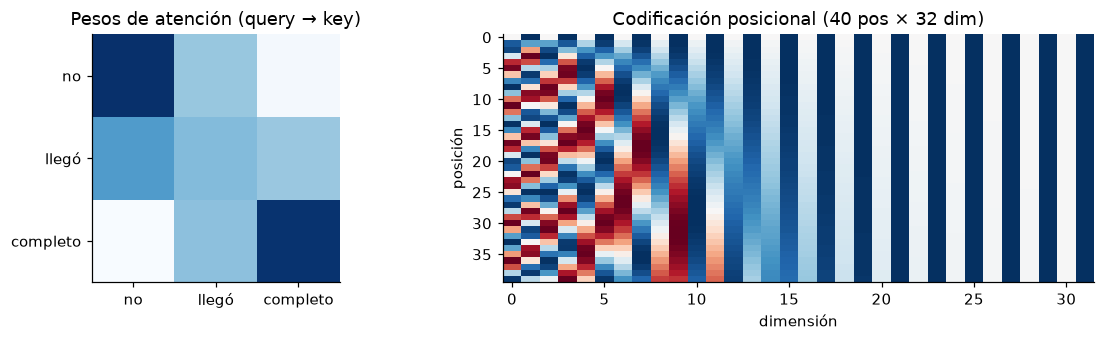

In [18]:
tokens_ej = ["no", "llegó", "completo"]
Q = np.array([[0.9, 0.1], [0.6, 0.4], [0.2, 0.9]])
K = np.array([[1.0, 0.0], [0.5, 0.5], [0.1, 1.0]])
V = np.array([[1.0, 0.0], [0.4, 0.6], [0.0, 1.0]])
scores = Q @ K.T / np.sqrt(K.shape[-1])
pesos_att = np.exp(scores - scores.max(1, keepdims=True)); pesos_att /= pesos_att.sum(1, keepdims=True)
contexto = pesos_att @ V
assert np.allclose(pesos_att.sum(1), 1.0)
print("Scores QK^T/sqrt(d):\n", scores.round(3)); print("Pesos (cada fila suma 1):\n", pesos_att.round(3))
print("Salida contextualizada de 'llegó':", contexto[1].round(3), "← mezcla de", dict(zip(tokens_ej, pesos_att[1].round(2))))

# Ejercicio 2: máscaras de relleno y causal
ids = np.array([101, 1520, 3014, 102, 0, 0]); mascara_relleno = (ids != 0).astype(int)
causal = np.tril(np.ones((6, 6), dtype=int))
s = np.random.default_rng(SEED).normal(size=(6, 6)); s_mask = np.where(causal == 1, s, -1e9)
print("Máscara de relleno [CLS] el pedido [SEP] [PAD] [PAD]:", mascara_relleno)
print("Máscara causal (decoder tipo GPT):\n", causal)
print("Fila 3 tras softmax con máscara causal (posiciones futuras = 0):", (np.exp(s_mask[2]) / np.exp(s_mask[2]).sum()).round(3))

# Codificación posicional sinusoidal: sin ella, "no llegó completo" y "completo llegó no" serían iguales para la atención
pos = np.arange(40)[:, None]; dim = np.arange(32)[None, :]
ang = pos / np.power(10000, (2 * (dim // 2)) / 32); pe = np.where(dim % 2 == 0, np.sin(ang), np.cos(ang))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].imshow(pesos_att, cmap="Blues"); ax[0].set_xticks(range(3), tokens_ej); ax[0].set_yticks(range(3), tokens_ej)
ax[0].set_title("Pesos de atención (query → key)")
ax[1].imshow(pe, aspect="auto", cmap="RdBu"); ax[1].set_title("Codificación posicional (40 pos × 32 dim)")
ax[1].set_xlabel("dimensión"); ax[1].set_ylabel("posición"); plt.tight_layout(); plt.show()

## 6.2 BETO y auditoría del tokenizador (ejercicio 3)
**BETO** (`dccuchile/bert-base-spanish-wwm-cased`, Universidad de Chile) es un BERT *encoder-only* de 12 capas, 12 cabezas y 768
dimensiones, preentrenado con *Masked Language Modeling* sobre un corpus grande en español. Es el candidato natural porque el corpus es
100% español latinoamericano; se compara su tokenizador con el de un modelo multilingüe (XLM-RoBERTa).

El tokenizador **forma parte del modelo**: el costo, la latencia y el truncamiento se miden en *subpalabras*, no en palabras.

In [19]:
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained(BERT_CHECKPOINT)
terminos = ["envío", "malísimo", "pésimo", "pesimo", "exelente", "recomendadísimo", "decepcionante", "talle",
            "MercadoPago", "devolución", "no funciona", "😡"]
tokenizadores = {"BETO": tok}
try:
    tokenizadores["XLM-R"] = AutoTokenizer.from_pretrained("xlm-roberta-base")
except Exception as e:
    print("XLM-R no disponible:", e)
filas = []
for nombre_tok, tk in tokenizadores.items():
    for w in terminos:
        piezas = tk.tokenize(w)
        filas.append({"tokenizador": nombre_tok, "término": w, "subpalabras": " ".join(piezas), "n": len(piezas)})
aud_tok = pd.DataFrame(filas)
display(aud_tok.pivot(index="término", columns="tokenizador", values="subpalabras"))
print("Subpalabras promedio por término:", aud_tok.groupby("tokenizador").n.mean().round(2).to_dict())

muestra_tok = train.texto.sample(20000, random_state=SEED) if len(train) > 20000 else train.texto
long_tok = pd.Series([len(x) for x in tok(list(muestra_tok), truncation=False)["input_ids"]])
pal = muestra_tok.str.split().str.len()
audit["tokens_bert"] = {"p50": float(long_tok.quantile(.5)), "p95": float(long_tok.quantile(.95)), "p99": float(long_tok.quantile(.99)),
                        "subpalabras_por_palabra": float(long_tok.sum() / pal.sum()),
                        **{f"truncados_{L}": float((long_tok > L).mean()) for L in [64, 128, 256]}}
print(json.dumps(audit["tokens_bert"], indent=1))
MAX_LEN = 128 if audit["tokens_bert"]["p99"] > 64 else 64
print("max_length elegido:", MAX_LEN, "(trunca el", f"{audit['tokens_bert'][f'truncados_{MAX_LEN}']:.1%}", "de los comentarios)")

tokenizador,BETO,XLM-R
término,,
MercadoPago,Mercado ##P ##ag ##o,▁Mercado Pa go
decepcionante,decepcion ##ante,▁decepcion ante
devolución,devolución,▁devolución
envío,envío,▁envío
exelente,ex ##ele ##n ##te,▁ex ele nte
malísimo,mal ##ísimo,▁mal ísimo
no funciona,no funciona,▁no ▁funciona
pesimo,pes ##imo,▁pes imo
pésimo,pé ##si ##mo,▁pés imo


Subpalabras promedio por término: {'BETO': 2.25, 'XLM-R': 2.0}


{
 "p50": 40.0,
 "p95": 96.0,
 "p99": 154.0,
 "subpalabras_por_palabra": 1.325908154287831,
 "truncados_64": 0.17375,
 "truncados_128": 0.018,
 "truncados_256": 0.0013
}
max_length elegido: 128 (trunca el 1.8% de los comentarios)


## 6.3 Estrategia de adaptación: *fine-tuning* completo de BETO
| Estrategia | Parámetros ajustados | Costo | Adaptación |
|---|---|---|---|
| Extracción de características | solo clasificador | bajo | baja |
| Fine-tuning parcial | últimas capas + clasificador | medio | media |
| **Fine-tuning completo (elegido)** | todo el modelo | alto | alta |
| PEFT / LoRA | pocas matrices adicionales | bajo-medio | media-alta |

Se elige **fine-tuning completo** porque el modelo es de tamaño base (110 M de parámetros) y la tarea es de un dominio específico
(jerga de compras, errores ortográficos, ironía).

**Restricción de cómputo (documentada):** el experimento corre en un portátil **sin GPU**. Por eso BETO se ajusta con un
**subconjunto estratificado** de `N_TRAIN_BERT` comentarios de entrenamiento (no con los 340 mil). Para que la comparación sea justa,
también se entrena una **TF-IDF + Regresión Logística con exactamente el mismo subconjunto**.

**Hiperparámetros** (rango recomendado en la sesión 4): AdamW, *learning rate* 2e-5, *weight decay* 0,01, *warmup* 10% con
*scheduler* lineal, *batch* 16, *gradient clipping* 1,0, `max_length` elegido por percentiles, **padding dinámico**
(`DataCollatorWithPadding`) y agrupación por longitud. La pérdida es entropía cruzada **con pesos de clase** (igual que los demás
modelos). La mejor época se elige por F1 macro en **validación**; la prueba no se toca.

In [20]:
from datasets import Dataset
from transformers import (AutoModelForSequenceClassification, DataCollatorWithPadding, TrainingArguments,
                          Trainer, set_seed)
set_seed(SEED)
n_tb = min(N_TRAIN_BERT, len(train) - 3)
idx_tb = np.sort(train_test_split(np.arange(len(train)), train_size=n_tb, stratify=y_tr, random_state=SEED)[0])
n_ev = min(1500, len(idx_vc) - 3)
idx_ev = np.sort(train_test_split(np.arange(len(idx_vc)), train_size=n_ev, stratify=y_vc, random_state=SEED)[0])

def a_dataset(textos, etiquetas):
    ds = Dataset.from_dict({"texto": list(textos), "label": [id_clase[c] for c in etiquetas]})
    return ds.map(lambda b: tok(b["texto"], truncation=True, max_length=MAX_LEN), batched=True, remove_columns=["texto"])

ds_train = a_dataset(train.texto.values[idx_tb], y_tr[idx_tb])
ds_eval = a_dataset(val.texto.values[idx_vc][idx_ev], y_vc[idx_ev])
pesos_bert = torch.tensor([n_tb / (3 * (y_tr[idx_tb] == c).sum()) for c in CLASES], dtype=torch.float)
print("Entrenamiento BETO:", len(ds_train), "| evaluación por época:", len(ds_eval),
      "| distribución:", pd.Series(y_tr[idx_tb]).value_counts(normalize=True).round(3).to_dict())

bert = AutoModelForSequenceClassification.from_pretrained(
    BERT_CHECKPOINT, num_labels=3, id2label=dict(enumerate(CLASES)), label2id=id_clase)
print("Parámetros BETO:", f"{bert.num_parameters():,}")

class TrainerPonderado(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        etiquetas = inputs.pop("labels")
        salida = model(**inputs)
        perdida = torch.nn.functional.cross_entropy(salida.logits, etiquetas, weight=pesos_bert.to(salida.logits.device))
        return (perdida, salida) if return_outputs else perdida

def metricas_hf(eval_pred):
    logits, etiquetas = eval_pred
    pred = logits.argmax(-1)
    return {"accuracy": accuracy_score(etiquetas, pred), "f1_macro": f1_score(etiquetas, pred, average="macro"),
            "recall_negativo": recall_score(etiquetas, pred, labels=[0], average=None)[0]}

args = TrainingArguments(
    output_dir="modelos/beto_checkpoints", learning_rate=2e-5, per_device_train_batch_size=16,
    per_device_eval_batch_size=64, num_train_epochs=EPOCAS_BERT, weight_decay=0.01, warmup_steps=0.1,   # float < 1 = 10% de los pasos
    lr_scheduler_type="linear", max_grad_norm=1.0, eval_strategy="epoch", save_strategy="epoch", save_total_limit=1,
    load_best_model_at_end=True, metric_for_best_model="f1_macro", greater_is_better=True,
    train_sampling_strategy="group_by_length",
    logging_steps=200, seed=SEED, report_to="none", disable_tqdm=True, dataloader_num_workers=0,
    use_cpu=not torch.cuda.is_available())
trainer = TrainerPonderado(model=bert, args=args, train_dataset=ds_train, eval_dataset=ds_eval,
                           processing_class=tok, data_collator=DataCollatorWithPadding(tok), compute_metrics=metricas_hf)
t = time.time()
salida_train = trainer.train()
seg_bert = time.time() - t
historia_bert = [h for h in trainer.state.log_history if "eval_f1_macro" in h or "loss" in h]
print(f"Entrenamiento BETO: {seg_bert/60:.1f} min")
display(pd.DataFrame([h for h in trainer.state.log_history if "eval_f1_macro" in h])
        [["epoch", "eval_loss", "eval_f1_macro", "eval_recall_negativo"]].round(4))
bert = trainer.model.eval()
trainer.save_model("modelos/beto_sentimiento"); tok.save_pretrained("modelos/beto_sentimiento")

Entrenamiento BETO: 16000 | evaluación por época: 1500 | distribución: {'positivo': 0.4, 'negativo': 0.399, 'neutro': 0.2}


Parámetros BETO: 109,853,187


{'loss': '0.9307', 'grad_norm': '10.82', 'learning_rate': '1.99e-05', 'epoch': '0.2'}


{'loss': '0.6591', 'grad_norm': '2.859', 'learning_rate': '1.779e-05', 'epoch': '0.4'}


{'loss': '0.5983', 'grad_norm': '8.362', 'learning_rate': '1.557e-05', 'epoch': '0.6'}


{'loss': '0.5637', 'grad_norm': '2.718', 'learning_rate': '1.334e-05', 'epoch': '0.8'}


... (8 outputs left out)

{'train_runtime': '6502', 'train_samples_per_second': '4.921', 'train_steps_per_second': '0.308', 'train_loss': '0.538', 'epoch': '2'}


Entrenamiento BETO: 108.4 min


,epoch,eval_loss,eval_f1_macro,eval_recall_negativo
0,1.0,0.4999,0.7822,0.9098
1,2.0,0.4564,0.7946,0.8431


('modelos/beto_sentimiento\\tokenizer_config.json',
 'modelos/beto_sentimiento\\tokenizer.json')

In [21]:
@torch.no_grad()
def bert_logits(textos, max_len=None, bs=64, modelo=None):
    modelo = modelo or bert
    textos = list(textos); orden = np.argsort([len(s) for s in textos]); out = np.zeros((len(textos), 3), dtype=np.float32)
    for i in range(0, len(textos), bs):
        idx = orden[i:i + bs]
        b = tok([textos[j] for j in idx], truncation=True, max_length=max_len or MAX_LEN, padding=True, return_tensors="pt")
        out[idx] = modelo(**b).logits.float().numpy()
    return out

def softmax(z, T=1.0):
    z = z / T; e = np.exp(z - z.max(1, keepdims=True)); return e / e.sum(1, keepdims=True)

t = time.time()
logits_vc = bert_logits(val.texto.values[idx_vc]); logits_tc = bert_logits(test.texto.values[idx_tc])
print(f"Inferencia BETO sobre {len(idx_vc) + len(idx_tc)} comentarios: {time.time() - t:.0f} s")
P_vc_bert, P_tc_bert = softmax(logits_vc), softmax(logits_tc)
predictores["BETO"] = lambda textos: softmax(bert_logits(textos, bs=32))
p50, p95, thr = latencia(predictores["BETO"], textos_test)
tam_bert = sum(os.path.getsize(os.path.join("modelos/beto_sentimiento", f)) for f in os.listdir("modelos/beto_sentimiento")) / 1e6

# Sensibilidad a la longitud: el mismo modelo con max_length=64 en inferencia
P64 = softmax(bert_logits(test.texto.values[idx_tc], max_len=64))
sens_long = {"f1_128": f1_score(y_tc, np.array(CLASES)[P_tc_bert.argmax(1)], average="macro"),
             "f1_64": f1_score(y_tc, np.array(CLASES)[P64.argmax(1)], average="macro")}
print("F1 macro (prueba común) con max_length 128 vs 64:", {k: round(v, 4) for k, v in sens_long.items()})

# Eficiencia (punto 29): cuantización dinámica int8 de las capas lineales, solo para inferencia en CPU
try:
    bert_q = torch.ao.quantization.quantize_dynamic(bert, {torch.nn.Linear}, dtype=torch.qint8)
    t = time.time()
    P_vc_q = softmax(bert_logits(val.texto.values[idx_vc], modelo=bert_q))
    P_tc_q = softmax(bert_logits(test.texto.values[idx_tc], modelo=bert_q))
    print(f"Inferencia BETO int8: {time.time() - t:.0f} s")
    predictores["BETO int8"] = lambda textos: softmax(bert_logits(textos, bs=32, modelo=bert_q))
    torch.save(bert_q.state_dict(), "modelos/beto_int8_state.pt")
    p50q, p95q, thrq = latencia(predictores["BETO int8"], textos_test)
    tam_q = os.path.getsize("modelos/beto_int8_state.pt") / 1e6
except Exception as e:
    print("Cuantización no disponible en este entorno:", e); bert_q = None

Inferencia BETO sobre 10000 comentarios: 552 s


F1 macro (prueba común) con max_length 128 vs 64: {'f1_128': 0.793, 'f1_64': 0.7921}


Inferencia BETO int8: 298 s


## 6.4 Comparación justa sobre la **misma** validación y prueba comunes
Además de los cinco modelos anteriores (entrenados con los 340 mil comentarios) se agrega una **TF-IDF + Regresión Logística entrenada
con el mismo subconjunto que BETO**: así se separa el efecto de "más datos" del efecto de "mejor arquitectura".

In [22]:
C_lr = mejores["TF-IDF + Regresión Logística"][1]
t = time.time()
lr_sub = Pipeline([("tfidf", tfidf()), ("clf", LogisticRegression(C=C_lr, max_iter=300, class_weight="balanced"))]).fit(
    train.texto.values[idx_tb], y_tr[idx_tb])
seg_lr_sub = time.time() - t
nombre_sub = f"TF-IDF + LR ({n_tb//1000}k, mismo subconjunto)"
predictores[nombre_sub] = predictor_sklearn(lr_sub)

# probabilidades sobre validación y prueba comunes para TODOS los modelos
P_comun = {k: (probas[k][0][idx_vc], probas[k][1][idx_tc]) for k in probas}
P_comun[nombre_sub] = (predictores[nombre_sub](val.texto.values[idx_vc]), predictores[nombre_sub](test.texto.values[idx_tc]))
P_comun["BETO"] = (P_vc_bert, P_tc_bert)
if bert_q is not None:
    P_comun["BETO int8"] = (P_vc_q, P_tc_q)

def ece(y, P, bins=15):
    conf = P.max(1); acierto = (np.array(CLASES)[P.argmax(1)] == np.asarray(y)); e = 0
    for a, b in zip(np.linspace(0, 1, bins + 1)[:-1], np.linspace(0, 1, bins + 1)[1:]):
        m = (conf > a) & (conf <= b)
        if m.any(): e += m.mean() * abs(acierto[m].mean() - conf[m].mean())
    return float(e)

comun = {}
for k, (Pv, Pt) in P_comun.items():
    pv, pt = np.array(CLASES)[Pv.argmax(1)], np.array(CLASES)[Pt.argmax(1)]
    comun[k] = {"val": metricas(y_vc, pv, Pv), "test": metricas(y_tc, pt, Pt), "ece_test": ece(y_tc, Pt)}
info = {k: {"seg_entreno": v["seg_entreno"], "p50": v["p50_ms_1"], "p95": v["p95_ms_1"], "thr": v["throughput_32"],
            "params": v["n_parametros"], "mb": v["tamano_mb"], "n_train": len(train)} for k, v in resultados.items()}
p50s, p95s, thrs = latencia(predictores[nombre_sub], textos_test)
info[nombre_sub] = {"seg_entreno": seg_lr_sub, "p50": p50s, "p95": p95s, "thr": thrs,
                    "params": int(lr_sub.named_steps["clf"].coef_.size), "mb": None, "n_train": n_tb}
info["BETO"] = {"seg_entreno": seg_bert, "p50": p50, "p95": p95, "thr": thr, "params": int(bert.num_parameters()),
                "mb": tam_bert, "n_train": n_tb}
if bert_q is not None:
    info["BETO int8"] = {"seg_entreno": seg_bert, "p50": p50q, "p95": p95q, "thr": thrq, "params": int(bert.num_parameters()),
                         "mb": tam_q, "n_train": n_tb}
tabla_c = pd.DataFrame([{"modelo": k, "datos entreno": info[k]["n_train"], "F1 val común": v["val"]["f1_macro"],
                         "F1 test común": v["test"]["f1_macro"], "F1 neg": v["test"]["f1_negativo"],
                         "F1 neu": v["test"]["f1_neutro"], "F1 pos": v["test"]["f1_positivo"],
                         "recall neg": v["test"]["recall_negativo"], "log loss": v["test"]["log_loss"], "ECE": v["ece_test"],
                         "entreno (min)": info[k]["seg_entreno"] / 60, "p95 ms": info[k]["p95"],
                         "coment./s (lote 32)": info[k]["thr"], "parámetros (M)": info[k]["params"] / 1e6}
                        for k, v in comun.items()]).sort_values("F1 val común", ascending=False)
tabla_c.to_csv("resultados/tabla_comparativa_s4.csv", index=False)
campeon = tabla_c.iloc[0]["modelo"]
print("Campeón por F1 macro en validación común:", campeon)
display(tabla_c.round(4))

Campeón por F1 macro en validación común: BETO


,modelo,datos entreno,F1 val común,F1 test común,F1 neg,F1 neu,F1 pos,recall neg,log loss,ECE,entreno (min),p95 ms,coment./s (lote 32),parámetros (M)
6,BETO,16000,0.7845,0.7930,0.8786,0.6237,0.8768,0.8538,0.4544,0.0564,108.3898,150.1447,8.7344,109.8532
7,BETO int8,16000,0.7803,0.7726,0.8782,0.5925,0.8472,0.8758,0.4617,0.0390,108.3898,121.2711,13.0223,109.8532
4,GRU,340634,0.7681,0.7584,0.8563,0.5840,0.8348,0.8237,0.4867,0.0400,11.8823,6.4834,763.8303,1.9452
3,LSTM,340634,0.7653,0.7656,0.8608,0.5779,0.8581,0.8327,0.4770,0.0241,9.3402,4.9481,1203.6999,1.9532
2,RNN,340634,0.7506,0.7529,0.8467,0.5692,0.8428,0.7982,0.5149,0.0249,5.4855,4.4021,1481.1564,1.9285
0,TF-IDF + Regresión Logística,340634,0.7366,0.7421,0.8317,0.5565,0.8382,0.7982,0.5505,0.0380,0.9419,1.0883,8369.3827,0.9000
1,TF-IDF + SVM lineal,340634,0.7289,0.7210,0.8372,0.4809,0.8449,0.8513,0.6040,0.1308,0.9933,1.1361,12806.1982,0.9000
5,"TF-IDF + LR (16k, mismo subconjunto)",16000,0.7011,0.7038,0.8145,0.4931,0.8038,0.7852,0.6675,0.1190,0.0506,1.3938,13955.4559,0.1034


### ¿La diferencia es real o es ruido? (intervalo de confianza por *bootstrap*)
Con 5.000 comentarios de prueba, una diferencia pequeña de F1 puede deberse al azar. Se remuestrea la prueba común 1.000 veces y se
calcula el intervalo del 95% para la diferencia de F1 macro entre BETO y el campeón secuencial.

In [23]:
def bootstrap_dif(y, pa, pb, n=1000):
    rng = np.random.default_rng(SEED); y, pa, pb = map(np.asarray, (y, pa, pb)); difs = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        difs.append(f1_score(y[i], pa[i], average="macro") - f1_score(y[i], pb[i], average="macro"))
    return float(np.mean(difs)), float(np.percentile(difs, 2.5)), float(np.percentile(difs, 97.5))
pred_c = {k: np.array(CLASES)[P_comun[k][1].argmax(1)] for k in P_comun}
ic = {f"BETO - {campeon_s3}": bootstrap_dif(y_tc, pred_c["BETO"], pred_c[campeon_s3]),
      f"BETO - {base}": bootstrap_dif(y_tc, pred_c["BETO"], pred_c[base]),
      f"{campeon_s3} - {base}": bootstrap_dif(y_tc, pred_c[campeon_s3], pred_c[base])}
for k, (m, a, b) in ic.items():
    print(f"{k:45s} ΔF1 = {m:+.4f}  IC95% [{a:+.4f}, {b:+.4f}]  {'(significativa)' if a > 0 or b < 0 else '(no concluyente)'}")

BETO - GRU                                    ΔF1 = +0.0350  IC95% [+0.0243, +0.0453]  (significativa)
BETO - TF-IDF + Regresión Logística           ΔF1 = +0.0511  IC95% [+0.0384, +0.0627]  (significativa)
GRU - TF-IDF + Regresión Logística            ΔF1 = +0.0160  IC95% [+0.0041, +0.0273]  (significativa)


## 6.5 Calibración (sesión 4, punto 26)
Las probabilidades de softmax suelen ser **demasiado confiadas**. Un modelo calibrado acierta ~80% de las veces cuando dice 0,8.
Se aplica **temperature scaling**: se busca una temperatura $T$ que minimice la pérdida logarítmica en **validación común**
($p = \mathrm{softmax}(z/T)$). No cambia la clase predicha, solo la confianza, que es la base de la abstención. Se mide con el
**ECE** (*expected calibration error*).

,T,ece_antes,ece_despues,logloss_antes,logloss_despues
TF-IDF + Regresión Logística,0.8555,0.0380,0.0126,0.5505,0.5452
GRU,1.0540,0.0400,0.0393,0.4867,0.4860
"TF-IDF + LR (16k, mismo subconjunto)",0.5829,0.1190,0.0117,0.6675,0.6166
BETO,1.3354,0.0564,0.0265,0.4544,0.4346
BETO int8,1.1345,0.0390,0.0301,0.4617,0.4579


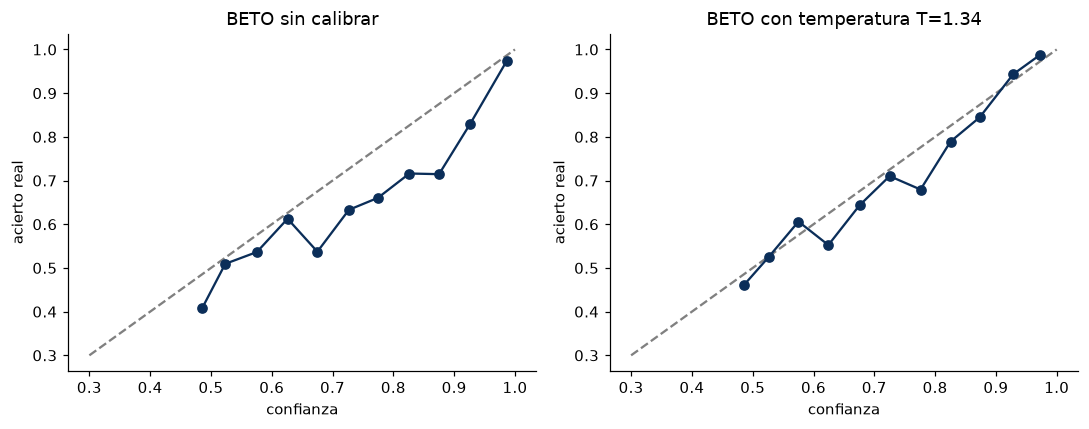

In [24]:
def ajustar_T(y, P):
    z = np.log(np.clip(P, 1e-9, 1)); yi = np.array([id_clase[c] for c in y])
    nll = lambda logT: log_loss(yi, softmax(z, np.exp(logT)), labels=[0, 1, 2])
    return float(np.exp(minimize_scalar(nll, bounds=(-2, 2), method="bounded").x))

calib, P_cal = {}, {}
for k in [base, campeon_s3, nombre_sub, "BETO"] + (["BETO int8"] if bert_q is not None else []):
    Pv, Pt = P_comun[k]
    T = ajustar_T(y_vc, Pv)
    Pv2, Pt2 = softmax(np.log(np.clip(Pv, 1e-9, 1)), T), softmax(np.log(np.clip(Pt, 1e-9, 1)), T)
    P_cal[k] = (Pv2, Pt2)
    calib[k] = {"T": T, "ece_antes": ece(y_tc, Pt), "ece_despues": ece(y_tc, Pt2),
                "logloss_antes": comun[k]["test"]["log_loss"],
                "logloss_despues": log_loss([id_clase[c] for c in y_tc], Pt2, labels=[0, 1, 2])}
display(pd.DataFrame(calib).T.round(4))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for i, (k, Pt) in enumerate([("BETO", P_comun["BETO"][1]), ("BETO", P_cal["BETO"][1])]):
    conf = Pt.max(1); ok = np.array(CLASES)[Pt.argmax(1)] == y_tc
    bordes = np.linspace(0.3, 1, 15); cx, cy = [], []
    for a, b in zip(bordes[:-1], bordes[1:]):
        m = (conf > a) & (conf <= b)
        if m.sum() > 20: cx.append(conf[m].mean()); cy.append(ok[m].mean())
    ax[i].plot([0.3, 1], [0.3, 1], "--", color="gray"); ax[i].plot(cx, cy, "o-", color="#0B2E59")
    T_beto = calib["BETO"]["T"]
    ax[i].set_title("BETO sin calibrar" if i == 0 else f"BETO con temperatura T={T_beto:.2f}")
    ax[i].set_xlabel("confianza"); ax[i].set_ylabel("acierto real")
plt.tight_layout(); plt.savefig("resultados/figuras/calibracion.png", dpi=150); plt.show()

## 6.6 Abstención y curva calidad-cobertura (ejercicio 7)
Criterio de la sesión 4: **recall de la clase crítica ≥ 0,92** en los comentarios que el modelo decide solo, con **cobertura automática
≥ 75%**. El umbral se elige en **validación común** (probabilidades calibradas) y se reporta en **prueba común**.

,modelo,umbral,cobertura,revisión por cada 1.000,recall neg auto,F1 macro auto,accuracy auto
0,TF-IDF + Regresión Logística,0.71,0.603,397,0.930,0.831,0.896
1,GRU,0.68,0.713,287,0.931,0.842,0.884
2,"TF-IDF + LR (16k, mismo subconjunto)",0.72,0.537,463,0.926,0.806,0.889
3,BETO,0.69,0.783,217,0.922,0.848,0.890
4,BETO int8,0.62,0.831,169,0.928,0.827,0.863


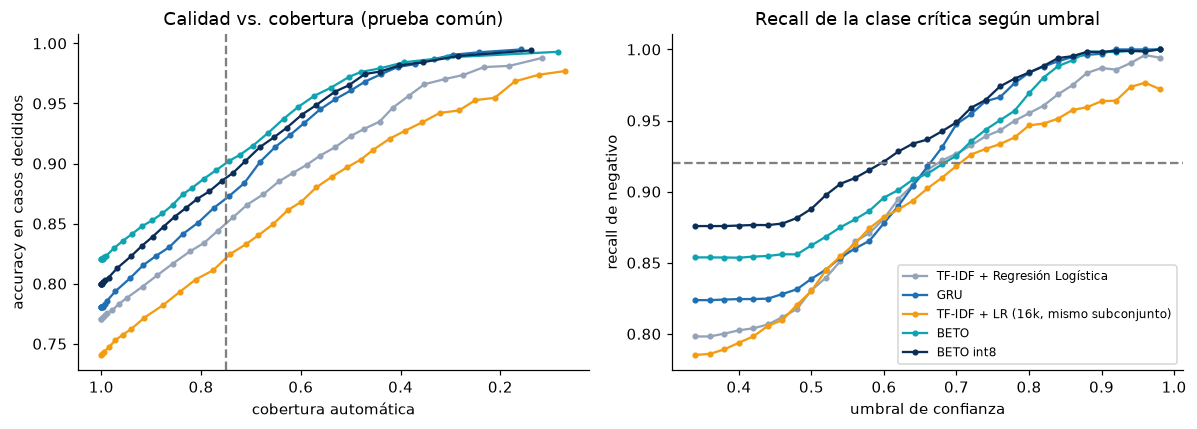

In [25]:
abst4 = {k: elegir_umbral(y_vc, P_cal[k][0], y_tc, P_cal[k][1], 0.92) for k in P_cal}
filas = []
for k, a in abst4.items():
    r = a["test"]
    filas.append({"modelo": k, "umbral": a["umbral"], "cobertura": r and r["cobertura"],
                  "revisión por cada 1.000": r and round(1000 * r["abstencion"]), "recall neg auto": r and r["recall_neg_auto"],
                  "F1 macro auto": r and r["f1_macro_auto"], "accuracy auto": r and r["accuracy_auto"]})
tabla_abst = pd.DataFrame(filas); display(tabla_abst.round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for k, col in zip(P_cal, ["#94A3B8", "#1F6FB2", "#F39C12", "#0FA3B1", "#0B2E59"]):
    curva = [g for g in (con_umbral(y_tc, P_cal[k][1], u) for u in np.arange(0.34, 0.99, 0.02)) if g]
    ax[0].plot([g["cobertura"] for g in curva], [g["accuracy_auto"] for g in curva], "o-", ms=3, label=k, color=col)
    ax[1].plot([g["umbral"] for g in curva], [g["recall_neg_auto"] for g in curva], "o-", ms=3, label=k, color=col)
ax[0].set_xlabel("cobertura automática"); ax[0].set_ylabel("accuracy en casos decididos"); ax[0].invert_xaxis()
ax[0].axvline(.75, ls="--", color="gray"); ax[0].set_title("Calidad vs. cobertura (prueba común)")
ax[1].axhline(.92, ls="--", color="gray"); ax[1].set_xlabel("umbral de confianza"); ax[1].set_ylabel("recall de negativo")
ax[1].set_title("Recall de la clase crítica según umbral"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig("resultados/figuras/abstencion.png", dpi=150); plt.show()

## 6.7 Perfil de eficiencia y frontera calidad-costo (ejercicio 9)
Latencia de **un comentario a la vez** (p50 y p95, CPU), *throughput* en lotes de 32, parámetros y tamaño del artefacto.
El costo por millón de comentarios se estima con un supuesto explícito: **una instancia de 4 vCPU a US$0,20/hora** procesando con el
*throughput* medido en este equipo.

,modelo,F1 test común,p50 ms,p95 ms,coment./s,parámetros (M),tamaño (MB),memoria pesos fp32 (MB),USD por millón,dominado
0,TF-IDF + Regresión Logística,0.742,0.544,1.088,8369.383,0.900,10.774,3.600,0.007,False
1,TF-IDF + SVM lineal,0.721,0.566,1.136,12806.198,0.900,10.778,3.600,0.004,True
5,"TF-IDF + LR (16k, mismo subconjunto)",0.704,0.621,1.394,13955.456,0.103,1.181,0.413,0.004,True
2,RNN,0.753,3.386,4.402,1481.156,1.928,23.171,7.714,0.038,False
3,LSTM,0.766,3.733,4.948,1203.700,1.953,23.469,7.813,0.046,False
4,GRU,0.758,4.788,6.483,763.830,1.945,23.372,7.781,0.073,True
7,BETO int8,0.773,71.404,121.271,13.022,109.853,182.972,439.413,4.266,False
6,BETO,0.793,69.092,150.145,8.734,109.853,440.172,439.413,6.361,False


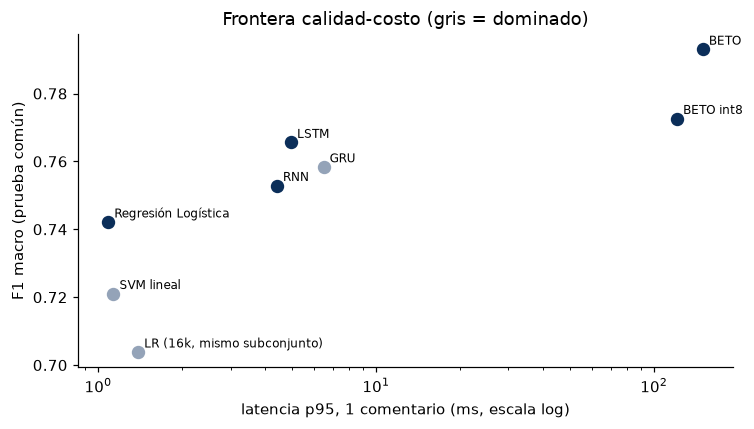

In [26]:
COSTO_HORA = float(os.environ.get("COSTO_HORA_USD", "0.20"))
ef = pd.DataFrame([{"modelo": k, "F1 test común": comun[k]["test"]["f1_macro"], "p50 ms": info[k]["p50"], "p95 ms": info[k]["p95"],
                    "coment./s": info[k]["thr"], "parámetros (M)": info[k]["params"] / 1e6, "tamaño (MB)": info[k]["mb"],
                    "memoria pesos fp32 (MB)": info[k]["params"] * 4 / 1e6,
                    "USD por millón": 1e6 / info[k]["thr"] / 3600 * COSTO_HORA} for k in comun]).sort_values("p95 ms")
ef["dominado"] = [bool(((ef["F1 test común"] > r["F1 test común"]) & (ef["p95 ms"] < r["p95 ms"])).any()) for _, r in ef.iterrows()]
ef.to_csv("resultados/eficiencia.csv", index=False); display(ef.round(3))
fig, ax = plt.subplots(figsize=(7, 4))
for _, r in ef.iterrows():
    ax.scatter(r["p95 ms"], r["F1 test común"], s=60, color="#94A3B8" if r["dominado"] else "#0B2E59")
    ax.annotate(r["modelo"].replace("TF-IDF + ", ""), (r["p95 ms"], r["F1 test común"]), fontsize=8, xytext=(4, 3), textcoords="offset points")
ax.set_xscale("log"); ax.set_xlabel("latencia p95, 1 comentario (ms, escala log)"); ax.set_ylabel("F1 macro (prueba común)")
ax.set_title("Frontera calidad-costo (gris = dominado)"); plt.tight_layout(); plt.savefig("resultados/figuras/frontera.png", dpi=150); plt.show()

## 6.8 Interpretabilidad: atención y oclusión (punto 28)
La matriz de atención muestra **qué tokens mezcla** cada posición, pero **no es una explicación causal**. Por eso se complementa con
**oclusión**: se borra cada palabra y se mide cuánto cae la probabilidad de la clase predicha.

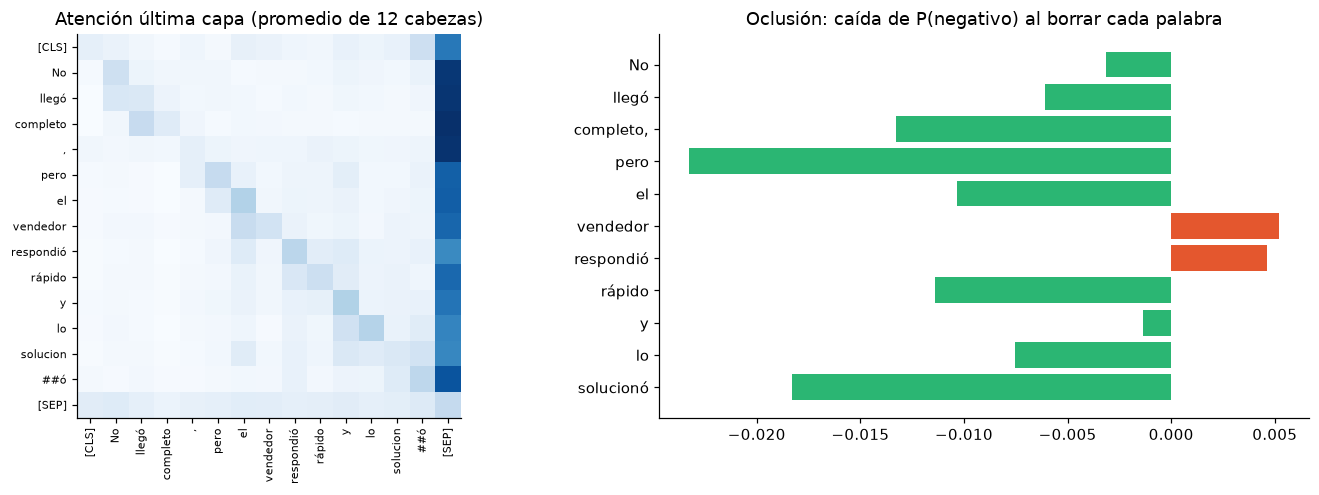

Predicción: negativo {'negativo': 0.97, 'neutro': 0.019, 'positivo': 0.011}


In [27]:
ejemplo = "No llegó completo, pero el vendedor respondió rápido y lo solucionó"
bert_att = AutoModelForSequenceClassification.from_pretrained("modelos/beto_sentimiento", attn_implementation="eager").eval()
b = tok(ejemplo, return_tensors="pt")
with torch.no_grad():
    o = bert_att(**b, output_attentions=True)
att = o.attentions[-1][0].mean(0).numpy(); toks = tok.convert_ids_to_tokens(b["input_ids"][0])
p_full = softmax(o.logits.numpy())[0]; clase_ej = CLASES[p_full.argmax()]
palabras_ej = ejemplo.split()
caidas = []
for i in range(len(palabras_ej)):
    p = predictores["BETO"]([" ".join(palabras_ej[:i] + palabras_ej[i + 1:])])[0]
    caidas.append(p_full[p_full.argmax()] - p[p_full.argmax()])
del bert_att; gc.collect()
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.1, 1]})
ax[0].imshow(att, cmap="Blues"); ax[0].set_xticks(range(len(toks)), toks, rotation=90, fontsize=7)
ax[0].set_yticks(range(len(toks)), toks, fontsize=7); ax[0].set_title("Atención última capa (promedio de 12 cabezas)")
ax[1].barh(palabras_ej[::-1], caidas[::-1], color=["#E4572E" if c > 0 else "#2BB673" for c in caidas[::-1]])
ax[1].set_title(f"Oclusión: caída de P({clase_ej}) al borrar cada palabra"); plt.tight_layout()
plt.savefig("resultados/figuras/interpretabilidad.png", dpi=150); plt.show()
print("Predicción:", clase_ej, {c: round(float(p), 3) for c, p in zip(CLASES, p_full)})

## 6.9 Extensión: clasificación de tokens y alineación BIO (ejercicio 8)
Siguiente paso del producto: **sentimiento por aspecto** (envío, calidad, precio, atención). Es una tarea de *token classification*:
cada palabra recibe una etiqueta BIO y las subpalabras se alinean con `word_ids()`. Se comparan dos políticas de alineación.

In [28]:
palabras_bio = ["El", "envío", "fue", "lentísimo", "pero", "la", "calidad", "es", "excelente"]
etiquetas_bio = ["O", "B-ENVIO", "O", "O", "O", "O", "B-CALIDAD", "O", "O"]
enc = tok(palabras_bio, is_split_into_words=True)
filas, previo = [], None
for pieza, wid in zip(tok.convert_ids_to_tokens(enc["input_ids"]), enc.word_ids()):
    if wid is None:
        p1 = p2 = -100
    elif wid != previo:
        p1 = p2 = etiquetas_bio[wid]
    else:
        p1 = -100; p2 = etiquetas_bio[wid].replace("B-", "I-")
    filas.append({"subpalabra": pieza, "word_id": wid, "solo primera subpalabra": p1, "propagar I-*": p2}); previo = wid
display(pd.DataFrame(filas))

,subpalabra,word_id,solo primera subpalabra,propagar I-*
0,[CLS],NaN,-100,-100
1,El,0.0,O,O
2,envío,1.0,B-ENVIO,B-ENVIO
3,fue,2.0,O,O
4,len,3.0,O,O
5,##tí,3.0,-100,O
6,##si,3.0,-100,O
7,##mo,3.0,-100,O
8,pero,4.0,O,O
9,la,5.0,O,O


# 7. Robustez y pruebas contrafactuales (ejercicio 6)
Pares mínimos que cambian (o no deberían cambiar) la etiqueta: negación, contraste, errores ortográficos, mayúsculas, emojis, ironía y
entradas **fuera de dominio**. Cada caso se cuenta en una sola de tres columnas: **acierta** (la clase correcta y decide solo, o se
abstiene cuando debía), **se abstiene** (manda a revisión un caso que sí tenía respuesta) o **falla**. Además repetimos los pares con
versiones largas (más de 15 palabras) para separar el efecto del contenido del efecto de la longitud.

## 7.1 Control de textos fuera de dominio
En la primera versión, BETO clasificaba *"La fotosíntesis depende de la energía solar"* como negativo con 0,94 de confianza: la
abstención por confianza no sirve para textos que no son reseñas, porque el modelo puede estar muy seguro de algo absurdo. Agregamos
un control **antes** de decidir: comparamos cada texto con 3.000 reseñas de entrenamiento usando la representación interna de BETO
(promedio de la última capa) y calculamos la similitud media con sus 5 vecinos más cercanos. Si queda por debajo del percentil 2 de
las reseñas de validación, el texto se marca como fuera de dominio y va a revisión humana. Para la versión sin BETO (demo web en
Render) usamos una señal más simple: la proporción de palabras que existen en el vocabulario de entrenamiento.

In [29]:
# 7.1 Control de fuera de dominio: similitud con reseñas de entrenamiento (k = 5 vecinos)
@torch.no_grad()
def bert_emb(textos, bs=64):
    textos = list(textos); o = np.argsort([len(s) for s in textos]); out = np.zeros((len(textos), 768), dtype=np.float32)
    for i in range(0, len(textos), bs):
        ix = o[i:i + bs]
        b = tok([textos[j] for j in ix], truncation=True, max_length=MAX_LEN, padding=True, return_tensors="pt")
        h = bert.bert(**b).last_hidden_state; m = b["attention_mask"].unsqueeze(-1)
        out[ix] = torch.nn.functional.normalize((h * m).sum(1) / m.sum(1), dim=1).numpy()
    return out
OOD = ["La fotosíntesis depende de la energía solar", "asdf qwerty 12345",
       "El partido terminó dos a uno y el delantero fue expulsado en el segundo tiempo",
       "Mañana va a llover en Bogotá según el pronóstico del clima", "Para preparar arepas se necesita harina de maíz, agua y sal",
       "def suma(a, b): return a + b", "The quick brown fox jumps over the lazy dog",
       "La reunión de la junta directiva se aplazó para el próximo martes", "El presidente anunció una reforma tributaria en el congreso",
       "Los planetas giran alrededor del sol en órbitas elípticas", "Mi gato duerme todo el día en el sofá de la sala",
       "Hoy aprendí a resolver ecuaciones de segundo grado en clase de matemáticas", "Bonjour, je voudrais un café s'il vous plaît",
       "La revolución francesa comenzó en 1789 con la toma de la Bastilla", "Necesito el certificado laboral para el trámite del banco",
       "Hola, ¿a qué hora abre la oficina el sábado?", "La teoría de la relatividad cambió la física moderna",
       "Receta: hornear el pastel a 180 grados durante 40 minutos", "El equipo de fútbol ganó el campeonato nacional después de diez años",
       "Las elecciones regionales serán en octubre del próximo año"]
rng_o = np.random.default_rng(SEED)
E_ref = bert_emb(train.texto.values[rng_o.choice(len(train), 3000, replace=False)])
sim_k = lambda E: np.sort(E @ E_ref.T, axis=1)[:, -5:].mean(1)
i_val, i_test = idx_vc[:2000], idx_tc[:2000]
s_val, s_test, s_ood = sim_k(bert_emb(val.texto.values[i_val])), sim_k(bert_emb(test.texto.values[i_test])), sim_k(bert_emb(OOD))
UMBRAL_OOD = float(np.percentile(s_val, 2))
# señal léxica para el modo sin BETO
tok_re = re.compile(r"(?u)\b\w\w+\b"); vocab_set = set(lr.named_steps["tfidf"].vocabulary_)
cobertura = lambda t: np.mean([w in vocab_set for w in tok_re.findall(t.lower())]) if tok_re.findall(t.lower()) else 0.0
c_val = np.array([cobertura(t) for t in val.texto.values[i_val]]); UMBRAL_COB = float(np.percentile(c_val, 2))
c_test, c_ood = np.array([cobertura(t) for t in test.texto.values[i_test]]), np.array([cobertura(t) for t in OOD])
ood_res = pd.DataFrame([
    {"método": "similitud BETO (k=5)", "umbral (p2 de validación)": UMBRAL_OOD, "reseñas de prueba marcadas": (s_test < UMBRAL_OOD).mean(),
     "textos fuera de dominio detectados": (s_ood < UMBRAL_OOD).mean()},
    {"método": "cobertura de vocabulario", "umbral (p2 de validación)": UMBRAL_COB, "reseñas de prueba marcadas": (c_test < UMBRAL_COB).mean(),
     "textos fuera de dominio detectados": (c_ood < UMBRAL_COB).mean()}])
display(ood_res.round(3))
display(pd.DataFrame({"texto": OOD, "similitud": s_ood.round(3), "detectado BETO": s_ood < UMBRAL_OOD,
                      "cobertura": c_ood.round(2), "detectado léxico": c_ood < UMBRAL_COB}))
np.save("resultados/ood_ref_emb.npy", E_ref.astype(np.float16))
json.dump({"emb": "resultados/ood_ref_emb.npy", "umbral_emb": UMBRAL_OOD, "k": 5, "umbral_cobertura": UMBRAL_COB},
          open("resultados/ood_referencia.json", "w"), indent=1)
es_ood = lambda textos: sim_k(bert_emb(textos)) < UMBRAL_OOD

,método,umbral (p2 de validación),reseñas de prueba marcadas,textos fuera de dominio detectados
0,similitud BETO (k=5),0.857,0.027,1.00
1,cobertura de vocabulario,0.909,0.019,0.45


,texto,similitud,detectado BETO,cobertura,detectado léxico
0,La fotosíntesis depende de la energía solar,0.813,True,0.86,True
1,asdf qwerty 12345,0.819,True,0.33,True
2,El partido terminó dos a uno y el delantero fu...,0.845,True,1.00,False
3,Mañana va a llover en Bogotá según el pronósti...,0.846,True,1.00,False
4,Para preparar arepas se necesita harina de maí...,0.828,True,1.00,False
5,"def suma(a, b): return a + b",0.799,True,0.33,True
6,The quick brown fox jumps over the lazy dog,0.829,True,0.78,True
7,La reunión de la junta directiva se aplazó par...,0.815,True,0.83,True
8,El presidente anunció una reforma tributaria e...,0.849,True,0.78,True
9,Los planetas giran alrededor del sol en órbita...,0.733,True,0.78,True


## 7.2 Resultados de los contrafactuales

In [30]:
casos = pd.DataFrame([
    ("negación", "El producto es excelente, lo recomiendo", "positivo"),
    ("negación", "El producto no es excelente, no lo recomiendo", "negativo"),
    ("contraste", "Pensé que sería malo, pero es excelente", "positivo"),
    ("contraste", "Pensé que sería excelente, pero es malo", "negativo"),
    ("ortografía", "exelente producto, lo recomiendo muxo", "positivo"),
    ("ortografía", "pesimo, no sirbe para nada", "negativo"),
    ("mayúsculas", "PÉSIMO, NO SIRVE, QUIERO MI DINERO", "negativo"),
    ("emoji", "Llegó roto 😡😡", "negativo"),
    ("ironía", "Genial, llegó roto y dos semanas tarde", "negativo"),
    ("neutro", "Cumple, aunque la tela es más delgada de lo que esperaba", "neutro"),
    ("larga", "Lo compré para mi hija. " * 8 + "Al final no funcionó y el vendedor nunca respondió", "negativo"),
    ("fuera de dominio", "La fotosíntesis depende de la energía solar", "abstención"),
    ("fuera de dominio", "asdf qwerty 12345", "abstención"),
    # versiones largas (> 15 palabras) de los mismos contrastes
    ("negación (larga)", "El producto es excelente, llegó bien empacado, funciona como dice la descripción y lo recomiendo a quien lo necesite", "positivo"),
    ("negación (larga)", "El producto no es excelente, llegó mal empacado, no funciona como dice la descripción y no lo recomiendo a nadie", "negativo"),
    ("contraste (largo)", "Pensé que sería malo porque el precio era muy bajo, pero es excelente, resistente y llegó antes de lo esperado", "positivo"),
    ("contraste (largo)", "Pensé que sería excelente porque tenía buenas opiniones, pero es malo, se rompió rápido y el vendedor no respondió", "negativo"),
    ("ortografía (larga)", "exelente producto, yego rapido y funsiona muy bien, lo recomiendo muxo a todos los que quieran uno igual", "positivo"),
    ("fuera de dominio (largo)", "El partido terminó dos a uno y el delantero fue expulsado en el segundo tiempo por una falta muy fuerte", "abstención")],
    columns=["caso", "texto", "esperado"])
modelos_rob = [base, campeon_s3, "BETO"]
umbral = {k: abst4[k]["umbral"] or 1.0 for k in modelos_rob}
ood_casos = es_ood(casos.texto)
resumen_rob = []
for k in modelos_rob:
    P = softmax(np.log(np.clip(predictores[k](casos.texto), 1e-9, 1)), calib[k]["T"])
    pred, conf = np.array(CLASES)[P.argmax(1)], P.max(1)
    abst = (conf < umbral[k]) | (ood_casos if k == "BETO" else False)
    casos[k] = [f"{p} ({c:.2f}){' → revisión' if a else ''}" for p, c, a in zip(pred, conf, abst)]
    estado = np.where(casos.esperado == "abstención", np.where(abst, "acierta", "falla"),
                      np.where(abst, "se abstiene", np.where(pred == casos.esperado, "acierta", "falla")))
    casos[f"estado_{k}"] = estado
    for grupo, m in [("cortos (≤ 15 palabras)", casos.texto.str.split().str.len() <= 15), ("largos (> 15 palabras)", casos.texto.str.split().str.len() > 15)]:
        e = pd.Series(estado[m.values])
        resumen_rob.append({"modelo": k, "grupo": grupo, "casos": int(m.sum()), "acierta": int((e == "acierta").sum()),
                            "se abstiene": int((e == "se abstiene").sum()), "falla": int((e == "falla").sum())})
casos["fuera de dominio (BETO)"] = ood_casos
pd.set_option("display.max_colwidth", 55)
display(casos[["caso", "texto", "esperado"] + modelos_rob + ["fuera de dominio (BETO)"]])
resumen_rob = pd.DataFrame(resumen_rob); display(resumen_rob)
robustez = {k: int((casos[f"estado_{k}"] == "acierta").sum()) for k in modelos_rob}
print("Casos acertados (de", len(casos), "):", robustez)

,caso,texto,esperado,TF-IDF + Regresión Logística,GRU,BETO,fuera de dominio (BETO)
0,negación,"El producto es excelente, lo recomiendo",positivo,positivo (0.99),negativo (0.84),negativo (0.90),False
1,negación,"El producto no es excelente, no lo recomiendo",negativo,negativo (0.99),negativo (1.00),negativo (0.98),False
2,contraste,"Pensé que sería malo, pero es excelente",positivo,positivo (0.49) → revisión,negativo (0.68) → revisión,negativo (0.92),False
3,contraste,"Pensé que sería excelente, pero es malo",negativo,neutro (0.53) → revisión,negativo (0.97),negativo (0.98),False
4,ortografía,"exelente producto, lo recomiendo muxo",positivo,negativo (0.91),negativo (0.91),negativo (0.95),False
5,ortografía,"pesimo, no sirbe para nada",negativo,negativo (1.00),negativo (1.00),negativo (0.98),False
6,mayúsculas,"PÉSIMO, NO SIRVE, QUIERO MI DINERO",negativo,negativo (1.00),negativo (1.00),negativo (0.97) → revisión,True
7,emoji,Llegó roto 😡😡,negativo,negativo (1.00),negativo (0.91),negativo (0.98),False
8,ironía,"Genial, llegó roto y dos semanas tarde",negativo,negativo (0.97),negativo (0.96),negativo (0.97),False
9,neutro,"Cumple, aunque la tela es más delgada de lo que esp...",neutro,neutro (0.66) → revisión,negativo (0.61) → revisión,negativo (0.74),False


,modelo,grupo,casos,acierta,se abstiene,falla
0,TF-IDF + Regresión Logística,cortos (≤ 15 palabras),12,7,3,2
1,TF-IDF + Regresión Logística,largos (> 15 palabras),7,4,2,1
2,GRU,cortos (≤ 15 palabras),12,6,2,4
3,GRU,largos (> 15 palabras),7,2,3,2
4,BETO,cortos (≤ 15 palabras),12,7,1,4
5,BETO,largos (> 15 palabras),7,3,3,1


Casos acertados (de 19 ): {'TF-IDF + Regresión Logística': 11, 'GRU': 8, 'BETO': 10}


**Lectura.** En los textos cortos, BETO y GRU responden "negativo" casi siempre, también ante los elogios: es el sesgo de longitud de la sección 8.1. Con las versiones largas, BETO deja de responder "negativo" a todo (el elogio largo sale positivo, con confianza baja, y la queja larga sale negativa), pero el contraste "Pensé que sería malo, pero es excelente" alargado todavía sale neutro: mejora, no lo resuelve. TF-IDF es el que más acierta en esta prueba (11 de 19) porque se apoya en palabras como "excelente". Los tres textos ajenos solo los manda a revisión BETO, gracias al control de fuera de dominio; GRU les asigna una etiqueta con confianza alta.

# 8. Análisis de errores con BETO (prueba común)
Se revisa **dónde** gana o pierde cada familia (longitud, negación, contraste, país, categoría) y se inspeccionan **20 errores
representativos** del campeón, etiquetados con una causa probable. La elección del modelo ya está congelada.

F1 macro por tramo


,TF-IDF + Regresión Logística,GRU,BETO
1-10,0.393,0.363,0.325
11-25,0.704,0.722,0.744
26-50,0.712,0.704,0.754
51-100,0.676,0.701,0.733
>100,0.466,0.617,0.609


F1 macro por negacion


,TF-IDF + Regresión Logística,GRU,BETO
False,0.757,0.785,0.813
True,0.731,0.742,0.782


F1 macro por contraste


,TF-IDF + Regresión Logística,GRU,BETO
False,0.747,0.762,0.798
True,0.676,0.702,0.741


F1 macro por country


,TF-IDF + Regresión Logística,GRU,BETO
MCO,0.740,0.764,0.796
MLA,0.757,0.781,0.813
MLC,0.694,0.689,0.747
MLM,0.747,0.755,0.789
MLU,0.684,0.698,0.721
MLV,0.675,0.708,0.768
MPE,0.829,0.877,0.879


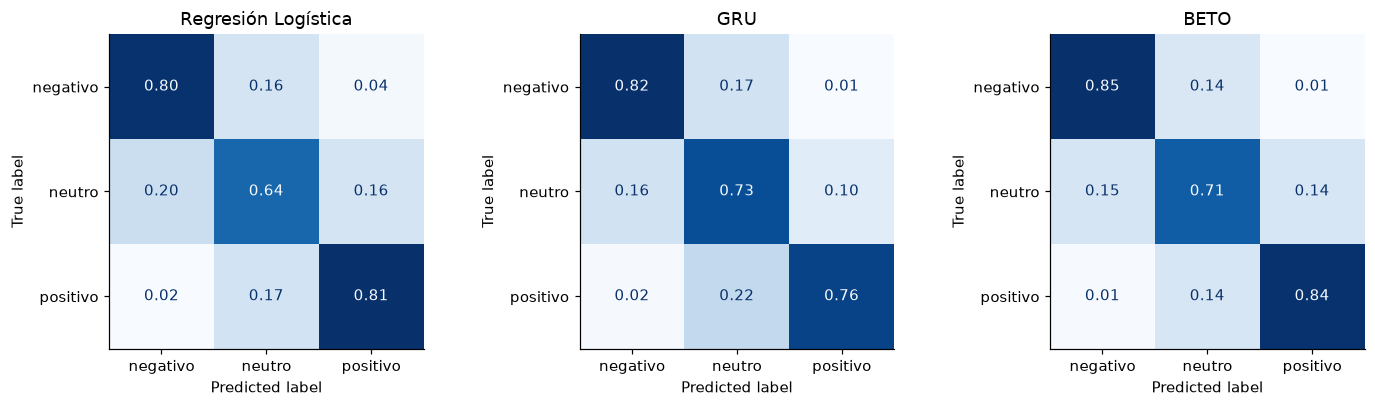

Negativos leídos como positivos (prueba común): {'TF-IDF + Regresión Logística': 76, 'TF-IDF + SVM lineal': 101, 'RNN': 41, 'LSTM': 35, 'GRU': 20, 'TF-IDF + LR (16k, mismo subconjunto)': 123, 'BETO': 18, 'BETO int8': 12}


In [31]:
tc = segmentar(test.iloc[idx_tc])
for k in [base, campeon_s3, "BETO"]:
    tc[k] = pred_c[k]
seg4 = {col: f1_por(tc, col, [base, campeon_s3, "BETO"]) for col in ["tramo", "negacion", "contraste", "country", "category"]}
for col in ["tramo", "negacion", "contraste", "country"]:
    print("F1 macro por", col); display(pd.DataFrame(seg4[col]).T.round(3))
cm_bert = confusion_matrix(y_tc, pred_c["BETO"], labels=CLASES)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
for a, k in zip(ax, [base, campeon_s3, "BETO"]):
    ConfusionMatrixDisplay(confusion_matrix(y_tc, pred_c[k], labels=CLASES, normalize="true"), display_labels=CLASES).plot(
        ax=a, colorbar=False, values_format=".2f", cmap="Blues")
    a.set_title(k.replace("TF-IDF + ", ""))
plt.tight_layout(); plt.savefig("resultados/figuras/confusion.png", dpi=150); plt.show()
neg_pos_c = {k: int(((y_tc == "negativo") & (pred_c[k] == "positivo")).sum()) for k in pred_c}
print("Negativos leídos como positivos (prueba común):", neg_pos_c)

In [32]:
def causa(r):
    # Clasificación automática y aproximada; la revisión hecha a mano está en la sección 8.2
    s = r.texto.lower()
    if len(s.split()) <= 15: return "texto corto (sesgo de longitud)"
    if re.search(r"\b(estrella|estrellas|[1-5] ?★)\b", s): return "menciona estrellas"
    if re.search(r"\b(pero|aunque|sin embargo)\b", s): return "contraste"
    if re.search(r"\b(no|nunca|ni|nada|tampoco)\b", s): return "negación"
    if r.review_rate == 3 or r.sentimiento == "neutro" or r.BETO == "neutro": return "frontera con neutro (3★ ambiguo)"
    return "otro / etiqueta ruidosa"
es_error = (tc.sentimiento != tc.BETO).values
err = tc[es_error].copy()
err["conf_BETO"] = P_cal["BETO"][1].max(1)[es_error]
err["causa"] = err.apply(causa, axis=1)
print("Errores de BETO en prueba común:", len(err), "de", len(tc))
display(err.causa.value_counts().rename("n").to_frame().assign(pct=lambda d: (d.n / d.n.sum()).round(3)))
print("Errores que la abstención habría mandado a revisión (confianza calibrada < umbral):",
      f"{(err.conf_BETO < abst4['BETO']['umbral']).mean():.1%}")
muestra_err = pd.concat([d.sample(min(len(d), 4), random_state=SEED) for _, d in err.groupby("causa")]).head(20)
display(muestra_err[["texto", "review_rate", "sentimiento", "BETO", "conf_BETO", campeon_s3, base, "causa"]].round(2))

Errores de BETO en prueba común: 899 de 5000


,n,pct
causa,,
contraste,417,0.464
negación,271,0.301
frontera con neutro (3★ ambiguo),123,0.137
texto corto (sesgo de longitud),57,0.063
menciona estrellas,25,0.028
otro / etiqueta ruidosa,6,0.007


Errores que la abstención habría mandado a revisión (confianza calibrada < umbral): 52.2%


,texto,review_rate,sentimiento,BETO,conf_BETO,GRU,TF-IDF + Regresión Logística,causa
344215,"El cable esta bien, lo compre para comprobar si mi ...",5,positivo,neutro,0.74,neutro,neutro,contraste
343635,No leí bien y terminé comprando un whiskey. Sabe pa...,3,neutro,positivo,0.74,neutro,positivo,contraste
317201,Buen producto solo que este modelo que pedi (h16) n...,4,positivo,neutro,0.60,neutro,neutro,contraste
241262,Linda. No es muy gruesa y esta cocida masomenos. Pe...,2,negativo,neutro,0.78,neutro,neutro,contraste
94716,Son de buena calidad para ejercicios básicos y case...,3,neutro,positivo,0.94,neutro,positivo,frontera con neutro (3★ ambiguo)
468465,Por el precio estodo loque dise aun que tiene que e...,4,positivo,neutro,0.71,negativo,negativo,frontera con neutro (3★ ambiguo)
360163,"Buen diseño atractivo buen audio, el microfono es i...",2,negativo,neutro,0.86,neutro,neutro,frontera con neutro (3★ ambiguo)
231249,"Quedan pequeños para alguien talla 38, dudo que a a...",4,positivo,neutro,0.78,neutro,positivo,frontera con neutro (3★ ambiguo)
30476,Son muy prácticas y realmente cumplirían su objetiv...,2,negativo,positivo,0.52,neutro,negativo,menciona estrellas
63674,Lo compré para donarlo. Lo regalé a una familia de ...,4,positivo,neutro,0.45,positivo,positivo,menciona estrellas


## 8.1 Hallazgo: sesgo de longitud en el corpus
Las pruebas contrafactuales mostraron que elogios cortos como *"El producto es excelente, lo recomiendo"* se clasifican como
**negativo**. La causa está en los datos: en MeLiSA casi todos los comentarios cortos tienen 1–2 estrellas y casi todos los positivos
son largos. Los modelos aprendieron el atajo **"texto corto ⇒ negativo"**. Es un sesgo de muestreo del corpus, no del idioma, y es
crítico para producción porque los chats y reclamos suelen ser cortos.

In [33]:
# 8.1 Sesgo de longitud: distribución de la etiqueta y desempeño por longitud
n_pal_all = df.texto.str.split().str.len()
tramos_l = pd.cut(n_pal_all, [0, 5, 10, 15, 25, 50, 10000], labels=["1-5", "6-10", "11-15", "16-25", "26-50", ">50"])
dist_long = pd.crosstab(tramos_l, df.sentimiento, normalize="index")[CLASES].round(3)
dist_long["comentarios"] = tramos_l.value_counts().sort_index()
print("Distribución de la etiqueta según el número de palabras (base limpia):")
display(dist_long)

es_corto = (tc.n_palabras <= 15).values
filas = []
for k in [base, campeon_s3, "BETO"]:
    for nombre, m in [("≤ 15 palabras", es_corto), ("> 15 palabras", ~es_corto)]:
        y, pr = tc.sentimiento.values[m], tc[k].values[m]
        filas.append({"modelo": k, "segmento": nombre, "n": int(m.sum()),
                      "% real negativo": (y == "negativo").mean(), "% predicho negativo": (pr == "negativo").mean(),
                      "recall positivo": ((pr == "positivo") & (y == "positivo")).sum() / max((y == "positivo").sum(), 1),
                      "F1 macro": f1_score(y, pr, average="macro")})
sesgo_long = pd.DataFrame(filas)
print("Prueba común por longitud:")
display(sesgo_long.round(3))

# Contrafactual de longitud: el mismo elogio, corto y con más contexto
pares = ["Excelente producto, lo recomiendo",
         "Excelente producto, lo recomiendo. Llegó a tiempo, bien empacado y funciona tal como dice la descripción; "
         "el vendedor respondió todas mis preguntas y lo volvería a comprar.",
         "Muy lindo, a la niña le encantó",
         "Muy lindo, a la niña le encantó. Los colores son iguales a los de la foto, el material se siente resistente, "
         "llegó antes de lo esperado y el tamaño es justo el que necesitábamos."]
cf_long = pd.DataFrame({"texto": [s[:70] + ("…" if len(s) > 70 else "") for s in pares],
                        "palabras": [len(s.split()) for s in pares]})
for k in [base, campeon_s3, "BETO"]:
    P = predictores[k](pares)
    cf_long[k] = [f"{CLASES[i]} ({c:.2f})" for i, c in zip(P.argmax(1), P.max(1))]
display(cf_long)
audit["sesgo_longitud"] = {"distribucion": {str(i): r.to_dict() for i, r in dist_long.iterrows()},
                           "pct_negativo_le15": float((df.sentimiento[n_pal_all <= 15] == "negativo").mean()),
                           "pct_corpus_le15": float((n_pal_all <= 15).mean()),
                           "modelos": sesgo_long.to_dict("records"), "contrafactual": cf_long.to_dict("records")}
print(f"Comentarios de ≤ 15 palabras: {audit['sesgo_longitud']['pct_corpus_le15']:.1%} del corpus; "
      f"de ellos, {audit['sesgo_longitud']['pct_negativo_le15']:.1%} son negativos.")

Distribución de la etiqueta según el número de palabras (base limpia):


sentimiento,negativo,neutro,positivo,comentarios
texto,,,,
1-5,0.930,0.025,0.045,4525
6-10,0.961,0.018,0.020,35537
11-15,0.921,0.059,0.020,44965
16-25,0.552,0.340,0.108,104185
26-50,0.210,0.211,0.579,216120
>50,0.145,0.160,0.695,81289


Prueba común por longitud:


,modelo,segmento,n,% real negativo,% predicho negativo,recall positivo,F1 macro
0,TF-IDF + Regresión Logística,≤ 15 palabras,868,0.935,0.849,0.429,0.481
1,TF-IDF + Regresión Logística,> 15 palabras,4132,0.287,0.266,0.811,0.732
2,GRU,≤ 15 palabras,868,0.935,0.956,0.095,0.470
3,GRU,> 15 palabras,4132,0.287,0.246,0.768,0.736
4,BETO,≤ 15 palabras,868,0.935,0.957,0.095,0.523
5,BETO,> 15 palabras,4132,0.287,0.255,0.852,0.775


,texto,palabras,TF-IDF + Regresión Logística,GRU,BETO
0,"Excelente producto, lo recomiendo",4,positivo (0.86),negativo (0.68),negativo (0.96)
1,"Excelente producto, lo recomiendo. Llegó a tie...",27,positivo (0.97),positivo (0.99),positivo (0.98)
2,"Muy lindo, a la niña le encantó",7,negativo (0.54),negativo (0.97),negativo (0.98)
3,"Muy lindo, a la niña le encantó. Los colores s...",34,positivo (0.87),positivo (0.95),positivo (0.98)


Comentarios de ≤ 15 palabras: 17.5% del corpus; de ellos, 93.8% son negativos.


## 8.2 Revisión manual de errores
La regla de arriba solo da una idea gruesa. Leímos uno por uno 20 errores de BETO (los de la muestra de la versión anterior) y
escribimos la causa con criterio propio. Lo que más aparece no es que el modelo "no entienda", sino tres cosas: comentarios cortos que
el sesgo de longitud empuja a negativo, opiniones mixtas en las que la etiqueta (las estrellas) es discutible, y detalles de dominio
o de ortografía que cambian el sentido.

In [34]:
revision_manual = [
    ("Me hizo sangrar la piel", "opinión mixta", "La queja (me cortó, me hizo sangrar) pesa más en el texto que el elogio; con 4★ la etiqueta es discutible."),
    ("Muy bueno pero las cartas", "texto corto + contraste", "Nueve palabras y un 'pero': el sesgo de longitud lo empuja a negativo."),
    ("Lo compré para mi perrita", "palabras negativas ajenas al producto", "La mascota murió: el modelo toma esa palabra como queja aunque el producto se elogia."),
    ("Hace 1 año q vengo luchando", "relato del problema previo", "Cuenta todo lo que no funcionó antes de este producto; la parte negativa ocupa más texto."),
    ("Buena relacion precio-calidad graba", "texto corto + comparación ambigua", "Comparar con 'celulares del 2008' puede leerse como crítica; además es corto."),
    ("Antes sabia mas a chilitos", "texto corto + contraste", "Empieza con una queja y termina elogiando; corto."),
    ("Muy lindo novedoso", "sesgo de longitud", "Elogio claro de 8 palabras leído como negativo con 0,98: el caso típico del atajo corto ⇒ negativo."),
    ("Perfecto, en buen estado", "sesgo de longitud", "Elogio de 7 palabras leído como negativo."),
    ("Buen material, buena calidad, sin embargo", "etiqueta discutible", "Describe un defecto que impide usarlo bien; neutro es una lectura razonable aunque tenga 4★."),
    ("El producto detecta las emisoras", "queja sin emoción", "Problema de compatibilidad contado en tono neutro; el modelo no ve palabras de enojo."),
    ("No era exactamente igual a la foto", "etiqueta ruidosa", "Tres quejas seguidas y 4★: la estrella no refleja el texto."),
    ("Son de buena calidad pero no se pudieron", "opinión mixta", "Elogio y defecto que impide el uso; neutro es defendible."),
    ("Son muy prácticas y realmente cumplirían", "condicional no captado", "'Cumplirían si fueran de mejor calidad' es una crítica en condicional; el modelo ve los elogios."),
    ("Lo compré para donarlo", "no evalúa el producto", "El autor dice que no lo ha usado y que pone estrellas 'para enviar el mensaje': no es una reseña."),
    ("Es corte recto, nada que ver", "menciona estrellas", "Explica por qué pone dos estrellas y no una; mezcla de queja y concesión."),
    ("Muy suaves, lo único es que", "opinión mixta (se abstendría)", "Muchos puntos en contra y cierre con 5★; confianza baja, la abstención lo manda a revisión."),
    ("La compré porque decía", "conocimiento de dominio", "'No es sin TACC' (no es apto para celíacos) es la queja principal y el modelo no conoce la sigla."),
    ("El taladro excelente, robusto", "opinión mixta", "Elogia el taladro y critica duro los accesorios; la etiqueta 4★ es discutible."),
    ("Cumple su función, no endurece", "negación de dominio", "'No endurece jamás' es el defecto principal de un sellador; el modelo lo lee como algo bueno."),
    ("Nos es muy fácil de manejar", "error ortográfico que invierte el sentido", "'Nos es' en vez de 'No es': el error convierte una queja en un elogio."),
]
filas_rm = []
for inicio, causa_m, comentario in revision_manual:
    fila = err[err.texto.str.startswith(inicio)]
    if len(fila):
        r0 = fila.iloc[0]
        filas_rm.append({"texto": r0.texto[:90] + ("…" if len(r0.texto) > 90 else ""), "★": r0.review_rate, "real": r0.sentimiento,
                         "BETO": r0.BETO, "conf.": round(float(r0.conf_BETO), 2), "palabras": len(r0.texto.split()),
                         "causa (revisión manual)": causa_m, "comentario": comentario})
revision = pd.DataFrame(filas_rm)
pd.set_option("display.max_colwidth", 120)
display(revision)
print(revision["causa (revisión manual)"].str.split(" \(").str[0].value_counts().to_string())

,texto,★,real,BETO,conf.,palabras,causa (revisión manual),comentario
0,"Me hizo sangrar la piel, me cortó. Afeita muy bien, pero los peines que traen son demasiad…",4,positivo,negativo,0.49,48,opinión mixta,"La queja (me cortó, me hizo sangrar) pesa más en el texto que el elogio; con 4★ la etiqueta es discutible."
1,Muy bueno pero las cartas algunas son muy malas.,4,positivo,negativo,0.98,9,texto corto + contraste,Nueve palabras y un 'pero': el sesgo de longitud lo empuja a negativo.
2,Lo compré para mi perrita fox terrier adulta y le gustó. Al poco tiempo murió y se la dimo…,5,positivo,negativo,0.60,45,palabras negativas ajenas al producto,La mascota murió: el modelo toma esa palabra como queja aunque el producto se elogia.
3,Hace 1 año q vengo luchando contra las cucas! probé de todo hasta un spray q lo pones y x …,5,positivo,negativo,0.49,91,relato del problema previo,Cuenta todo lo que no funcionó antes de este producto; la parte negativa ocupa más texto.
4,Buena relacion precio-calidad graba como celular de los del 2008 mas o menos.,4,positivo,negativo,0.55,13,texto corto + comparación ambigua,Comparar con 'celulares del 2008' puede leerse como crítica; además es corto.
5,Antes sabia mas a chilitos. En general aun asi es un gran producto.,4,positivo,negativo,0.59,13,texto corto + contraste,Empieza con una queja y termina elogiando; corto.
6,"Muy lindo novedoso, la niña se divierte mucho.",4,positivo,negativo,0.95,8,sesgo de longitud,"Elogio claro de 8 palabras leído como negativo con 0,98: el caso típico del atajo corto ⇒ negativo."
7,"Perfecto, en buen estado, ideal para apuntes.",5,positivo,negativo,0.74,7,sesgo de longitud,Elogio de 7 palabras leído como negativo.
8,"Buen material, buena calidad, sin embargo no se adhiere muy bien al piso y eso lo torna in…",4,positivo,neutro,0.87,20,etiqueta discutible,Describe un defecto que impide usarlo bien; neutro es una lectura razonable aunque tenga 4★.
9,"El producto detecta las emisoras, pero al momento de instalarlo en el auto no cabe en un a…",2,negativo,neutro,0.74,38,queja sin emoción,Problema de compatibilidad contado en tono neutro; el modelo no ve palabras de enojo.


causa (revisión manual)
opinión mixta                                4
texto corto + contraste                      2
sesgo de longitud                            2
palabras negativas ajenas al producto        1
relato del problema previo                   1
texto corto + comparación ambigua            1
etiqueta discutible                          1
queja sin emoción                            1
etiqueta ruidosa                             1
condicional no captado                       1
no evalúa el producto                        1
menciona estrellas                           1
conocimiento de dominio                      1
negación de dominio                          1
error ortográfico que invierte el sentido    1


## 8.3 Resumen agregado de opinión
La línea de análisis de opinión pide, además del resultado por comentario, un **resumen agregado**: lo que vería Gerencia en un
tablero. Comparamos la distribución de sentimiento real con la que estima BETO por país y por categoría, en la prueba común.

,country,comentarios,% negativo real,% negativo BETO,% positivo real,% positivo BETO,error % negativo (pp)
1,MLA,2190,0.397,0.364,0.408,0.406,-3.333
3,MLM,1502,0.399,0.361,0.402,0.370,-3.795
0,MCO,468,0.397,0.389,0.395,0.348,-0.855
2,MLC,466,0.408,0.408,0.391,0.290,0.000
4,MLU,272,0.408,0.482,0.360,0.294,7.353
5,MLV,62,0.371,0.355,0.403,0.290,-1.613
6,MPE,40,0.450,0.500,0.350,0.325,5.000


,category,comentarios,% negativo real,% negativo BETO,% positivo real,% positivo BETO,error % negativo (pp)
2,Hogar / Casa,1685,0.403,0.384,0.401,0.363,-1.899
4,Tecnología y electrónica / Tecnologia e electronica,1495,0.410,0.370,0.395,0.378,-4.013
3,"Salud, ropa y cuidado personal / Saúde, roupas e cuidado pessoal",1461,0.385,0.366,0.412,0.372,-1.916
1,Arte y entretenimiento / Arte e Entretenimiento,295,0.397,0.414,0.407,0.386,1.695
0,Alimentos y Bebidas / Alimentos e Bebidas,64,0.391,0.422,0.219,0.297,3.125


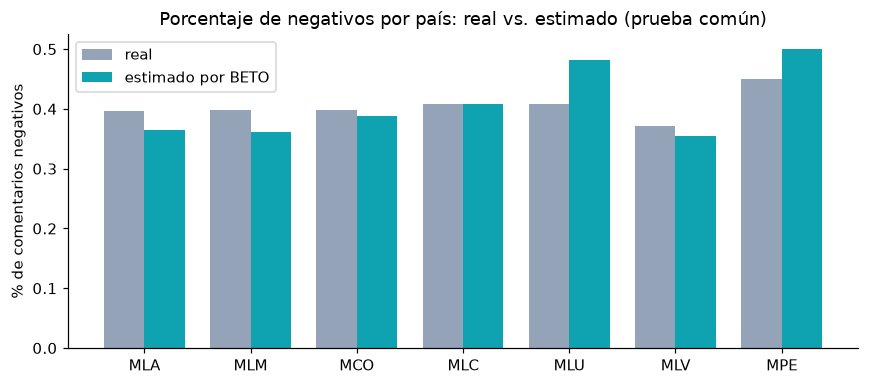

In [35]:
def resumen_por(col):
    filas = []
    for g, d in tc.groupby(col):
        filas.append({col: g, "comentarios": len(d), "% negativo real": (d.sentimiento == "negativo").mean(),
                      "% negativo BETO": (d.BETO == "negativo").mean(), "% positivo real": (d.sentimiento == "positivo").mean(),
                      "% positivo BETO": (d.BETO == "positivo").mean()})
    out = pd.DataFrame(filas)
    out["error % negativo (pp)"] = 100 * (out["% negativo BETO"] - out["% negativo real"])
    return out.sort_values("comentarios", ascending=False)
agg_pais, agg_cat = resumen_por("country"), resumen_por("category")
display(agg_pais.round(3)); display(agg_cat.round(3))
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(agg_pais)); w = 0.38
ax.bar(x - w / 2, agg_pais["% negativo real"], w, label="real", color="#94A3B8")
ax.bar(x + w / 2, agg_pais["% negativo BETO"], w, label="estimado por BETO", color="#0FA3B1")
ax.set_xticks(x, agg_pais.country); ax.set_ylabel("% de comentarios negativos"); ax.legend()
ax.set_title("Porcentaje de negativos por país: real vs. estimado (prueba común)")
plt.tight_layout(); plt.savefig("resultados/figuras/agregado_pais.png", dpi=150); plt.show()

# 9. Criterio de adopción de la sesión 4
> El Transformer avanza a **shadow mode** solo si mejora el F1 macro **al menos 0,02** frente al campeón anterior (secuencial),
> conserva **recall de negativo ≥ 0,92** bajo el umbral elegido, **latencia p95 ≤ 150 ms** y **cobertura automática ≥ 75%**.

Desde la formulación (sección 0) el proceso es **por lotes horarios**, así que agregamos un quinto criterio operativo que se fijó antes
de ver los resultados de BETO: **capacidad en lote**, procesar el volumen de una hora (unos 1.400 comentarios para un millón al mes)
en menos de 10 minutos con un solo proceso. La latencia en línea se sigue reportando tal como la pide el curso.

In [36]:
VOLUMEN_HORA = 1_000_000 / (30 * 24)
def evaluar_criterio(k, ref):
    a = abst4[k]["test"] or {}
    filas = [("Ganancia de calidad", f"F1 macro ≥ {ref} + 0,02", comun[k]["test"]["f1_macro"] - comun[ref]["test"]["f1_macro"], lambda v: v >= 0.02),
             ("Clase crítica con abstención", "recall negativo ≥ 0,92", a.get("recall_neg_auto", np.nan), lambda v: v >= 0.92),
             ("Cobertura automática", "≥ 75%", a.get("cobertura", np.nan), lambda v: v >= 0.75),
             ("Latencia en línea (CPU)", "p95 ≤ 150 ms", info[k]["p95"], lambda v: v <= 150),
             ("Capacidad en lote", "1 hora de volumen en < 10 min", VOLUMEN_HORA / info[k]["thr"] / 60, lambda v: v < 10)]
    return [{"modelo": k, "criterio": c, "umbral": u, "valor": v, "cumple": bool(f(v))} for c, u, v, f in filas]
variantes = ["BETO"] + (["BETO int8"] if "BETO int8" in comun else [])
criterio = pd.DataFrame(sum([evaluar_criterio(k, campeon_s3) for k in variantes], []) + evaluar_criterio(campeon_s3, base))
display(criterio.round(4))
nucleo = ["Ganancia de calidad", "Clase crítica con abstención", "Cobertura automática"]
pasa = {k: bool(criterio[criterio.modelo == k].cumple.all()) for k in variantes + [campeon_s3]}
pasa_lote = {k: bool(criterio[(criterio.modelo == k) & (criterio.criterio != "Latencia en línea (CPU)")].cumple.all()) for k in variantes + [campeon_s3]}
cumple_bert, cumple_s3 = any(pasa[k] for k in variantes), pasa[campeon_s3]
print("Cumplen los 4 criterios del curso:", pasa)
print("Cumplen calidad, clase crítica, cobertura y capacidad en lote:", pasa_lote)

,modelo,criterio,umbral,valor,cumple
0,BETO,Ganancia de calidad,"F1 macro ≥ GRU + 0,02",0.0347,True
1,BETO,Clase crítica con abstención,"recall negativo ≥ 0,92",0.9222,True
2,BETO,Cobertura automática,≥ 75%,0.7826,True
3,BETO,Latencia en línea (CPU),p95 ≤ 150 ms,150.1447,False
4,BETO,Capacidad en lote,1 hora de volumen en < 10 min,2.6502,True
5,BETO int8,Ganancia de calidad,"F1 macro ≥ GRU + 0,02",0.0143,False
6,BETO int8,Clase crítica con abstención,"recall negativo ≥ 0,92",0.9283,True
7,BETO int8,Cobertura automática,≥ 75%,0.8310,True
8,BETO int8,Latencia en línea (CPU),p95 ≤ 150 ms,121.2711,True
9,BETO int8,Capacidad en lote,1 hora de volumen en < 10 min,1.7776,True


Cumplen los 4 criterios del curso: {'BETO': False, 'BETO int8': False, 'GRU': False}
Cumplen calidad, clase crítica, cobertura y capacidad en lote: {'BETO': True, 'BETO int8': False, 'GRU': False}


### Lectura del criterio y decisión del comité
- **Con el criterio estricto del curso ningún modelo cumple todo.** BETO cumple calidad (+0,035 de F1 frente a GRU, IC 95% [0,024;
  0,045]), recall de negativo (0,922), cobertura (78,3%) y capacidad en lote, pero su latencia en línea en un portátil **sin GPU** es
  150,1 ms, una décima de milisegundo por encima del límite. BETO int8 cumple la latencia (121 ms), pero mejora solo +0,014. GRU no
  supera a la línea base por 0,02 ni llega al 75% de cobertura.
- El criterio de capacidad en lote no es un ajuste posterior: el modo de operación por lotes se fijó en la formulación (sección 0).
- **Decisión del comité (condicionada):** piloto de BETO en **modo sombra**, por lotes, con abstención (umbral 0,69), con el control
  de fuera de dominio de la sección 7.1 y sin alertas automáticas para comentarios de 15 palabras o menos (sección 8.1). TF-IDF + LR
  queda como respaldo. Si se necesitara responder en línea, se usaría BETO int8 o una GPU. La decisión está en
  `resultados/decision.json`, y tanto la sección 10 como `src/demo.py` y la demo web usan BETO.

# 10. Demostración del flujo completo
`predecir(texto)` reproduce lo que haría el servicio: valida la entrada, enmascara PII, **revisa si el texto está fuera de dominio**,
calcula probabilidades calibradas, aplica la **política de abstención**, bloquea las alertas automáticas en comentarios de 15 palabras
o menos (sesgo de longitud) y devuelve **evidencia** (las palabras que más pesaron según la regresión logística). Usa el modelo que
aprobó el comité, BETO, igual que `src/demo.py` y la demo web de `app/`.

In [37]:
MODELO_DEMO = json.load(open("resultados/decision.json", encoding="utf-8"))["modelo"] if os.path.exists("resultados/decision.json") else campeon_s3
print("Modelo usado en la demostración (decisión del comité):", MODELO_DEMO)
def evidencia_lr(texto, clase, n=4):
    x = lr.named_steps["tfidf"].transform([texto]); w = lr.named_steps["clf"].coef_[clases_lr.index(clase)]
    contrib = x.multiply(w).toarray()[0]; idx = np.argsort(contrib)[::-1][:n]
    return [vocab[i] for i in idx if contrib[i] > 0]

def predecir(texto, modelo=MODELO_DEMO):
    if not isinstance(texto, str) or len(texto.strip()) < 3:
        return {"estado": "error", "detalle": "texto vacío o demasiado corto", "decision": "revisión humana"}
    limpio = enmascarar(texto.strip())
    P = predictores[modelo]([limpio]); P = softmax(np.log(np.clip(P, 1e-9, 1)), calib[modelo]["T"])[0]
    clase, conf = CLASES[int(P.argmax())], float(P.max())
    u = abst4[modelo]["umbral"] or 1.0
    fuera = bool(es_ood([limpio])[0])
    corto = len(limpio.split()) <= 15
    automatica = conf >= u and not fuera
    return {"modelo": modelo, "texto": limpio[:120], "etiqueta": clase, "confianza": round(conf, 3),
            "probabilidades": {c: round(float(p), 3) for c, p in zip(CLASES, P)},
            "decision": "automática" if automatica else "revisión humana", "umbral": round(u, 2), "fuera_de_dominio": fuera,
            "alerta_vendedor": clase == "negativo" and automatica and not corto, "comentario_corto": corto,
            "evidencia": evidencia_lr(limpio, clase)}

for s in ["Lo usé una semana y dejó de funcionar. La calidad es pésima, el material se siente barato y no lo recomiendo para nada.",
          "Excelente producto, lo recomiendo",
          "Excelente producto, se nota la buena calidad del material, funciona tal como dice la descripción y lo recomiendo a quien lo necesite",
          "Dejó de funcionar a la semana y la calidad es muy mala, escríbanme a juan.perez@correo.com",
          "El paquete llegó tarde y el vendedor nunca respondió mis mensajes, pésimo servicio de entrega",
          "El partido terminó dos a uno y el delantero fue expulsado en el segundo tiempo por una falta muy fuerte",
          ""]:
    print(json.dumps(predecir(s), ensure_ascii=False))

Modelo usado en la demostración (decisión del comité): BETO


{"modelo": "BETO", "texto": "Lo usé una semana y dejó de funcionar. La calidad es pésima, el material se siente barato y no lo recomiendo para nada.", "etiqueta": "negativo", "confianza": 0.963, "probabilidades": {"negativo": 0.963, "neutro": 0.033, "positivo": 0.003}, "decision": "automática", "umbral": 0.69, "fuera_de_dominio": false, "alerta_vendedor": true, "comentario_corto": false, "evidencia": ["pésima", "para nada", "no lo", "de funcionar"]}
{"modelo": "BETO", "texto": "Excelente producto, lo recomiendo", "etiqueta": "negativo", "confianza": 0.907, "probabilidades": {"negativo": 0.907, "neutro": 0.025, "positivo": 0.068}, "decision": "automática", "umbral": 0.69, "fuera_de_dominio": false, "alerta_vendedor": false, "comentario_corto": true, "evidencia": ["lo recomiendo", "excelente producto", "producto lo", "producto"]}


{"modelo": "BETO", "texto": "Excelente producto, se nota la buena calidad del material, funciona tal como dice la descripción y lo recomiendo a quien", "etiqueta": "positivo", "confianza": 0.726, "probabilidades": {"negativo": 0.01, "neutro": 0.263, "positivo": 0.726}, "decision": "automática", "umbral": 0.69, "fuera_de_dominio": false, "alerta_vendedor": false, "comentario_corto": false, "evidencia": ["excelente", "la", "buena", "recomiendo"]}
{"modelo": "BETO", "texto": "Dejó de funcionar a la semana y la calidad es muy mala, escríbanme a <EMAIL>", "etiqueta": "negativo", "confianza": 0.975, "probabilidades": {"negativo": 0.975, "neutro": 0.021, "positivo": 0.004}, "decision": "automática", "umbral": 0.69, "fuera_de_dominio": false, "alerta_vendedor": false, "comentario_corto": true, "evidencia": ["mala", "muy mala", "de funcionar", "dejó de"]}


{"modelo": "BETO", "texto": "El paquete llegó tarde y el vendedor nunca respondió mis mensajes, pésimo servicio de entrega", "etiqueta": "negativo", "confianza": 0.981, "probabilidades": {"negativo": 0.981, "neutro": 0.015, "positivo": 0.004}, "decision": "automática", "umbral": 0.69, "fuera_de_dominio": false, "alerta_vendedor": false, "comentario_corto": true, "evidencia": ["pésimo", "nunca", "el paquete", "tarde"]}


{"modelo": "BETO", "texto": "El partido terminó dos a uno y el delantero fue expulsado en el segundo tiempo por una falta muy fuerte", "etiqueta": "negativo", "confianza": 0.923, "probabilidades": {"negativo": 0.923, "neutro": 0.063, "positivo": 0.014}, "decision": "revisión humana", "umbral": 0.69, "fuera_de_dominio": true, "alerta_vendedor": false, "comentario_corto": false, "evidencia": ["una falta", "en el", "terminó", "segundo"]}
{"estado": "error", "detalle": "texto vacío o demasiado corto", "decision": "revisión humana"}


In [38]:
def limpiar(o):
    if isinstance(o, dict): return {str(k): limpiar(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [limpiar(v) for v in o]
    if isinstance(o, (np.floating, np.integer)): return o.item()
    if isinstance(o, np.ndarray): return o.tolist()
    return o
salida = {"entorno": entorno, "audit": audit, "resultados_s3": resultados, "abstencion_s3": {k: {kk: vv for kk, vv in v.items() if kk != "curva"} for k, v in abstencion.items()},
          "analisis_s3": analisis, "busqueda_C": busqueda, "top_palabras": top, "historias_rnn": historias,
          "s4": {"max_len": MAX_LEN, "n_train_bert": n_tb, "seg_bert": seg_bert, "historia_bert": historia_bert,
                 "aud_tokenizador": aud_tok.to_dict("records"), "sens_longitud": sens_long, "comun": comun, "info": info,
                 "campeon": campeon, "campeon_s3": campeon_s3, "base": base, "nombre_sub": nombre_sub,
                 "ic_bootstrap": ic, "calibracion": calib,
                 "abstencion": {k: {kk: vv for kk, vv in v.items() if kk != "curva"} for k, v in abst4.items()},
                 "curvas": {k: [g for g in (con_umbral(y_tc, P_cal[k][1], u) for u in np.arange(0.34, 0.99, 0.02)) if g] for k in P_cal},
                 "eficiencia": ef.to_dict("records"), "robustez": robustez,
                 "casos_robustez": casos.drop(columns=[c for c in casos if c.startswith("ok_")]).to_dict("records"),
                 "segmentos": seg4, "cm": {k: confusion_matrix(y_tc, pred_c[k], labels=CLASES).tolist() for k in pred_c},
                 "neg_como_pos": neg_pos_c, "errores_causas": err.causa.value_counts().to_dict(),
                 "errores_muestra": muestra_err[["texto", "review_rate", "sentimiento", "BETO", "conf_BETO", "causa"]].to_dict("records"),
                 "criterio": criterio.to_dict("records"), "cumple_bert": cumple_bert, "cumple_s3": cumple_s3, "pasa": pasa,
                 "modelo_demo": MODELO_DEMO, "umbral_demo": abst4[MODELO_DEMO]["umbral"], "T_demo": calib[MODELO_DEMO]["T"]},
          "minutos_totales": (time.time() - T_INICIO) / 60}
json.dump(limpiar(salida), open("resultados/resultados.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1, default=str)
json.dump({"modelo": MODELO_DEMO, "umbral": abst4[MODELO_DEMO]["umbral"], "temperatura": calib[MODELO_DEMO]["T"],
           "max_len": MAX_LEN, "clases": CLASES}, open("modelos/config_demo.json", "w"), indent=1)
print(f"Guardado en resultados/ · tiempo total del notebook: {salida['minutos_totales']:.0f} min")

Guardado en resultados/ · tiempo total del notebook: 173 min


# 11. Conclusiones por rol

### Pedro García Romero · Especialista en Machine Learning
- Sobre la **misma prueba común** de 5.000 comentarios, BETO llega a **F1 macro 0,793**: 0,758 de GRU (el mejor recurrente en
  validación), 0,766 de LSTM y 0,742 de TF-IDF + LR. La ventaja sobre GRU es **+0,035, IC 95% [0,024; 0,045]**.
- Lo más valioso del Transformer es el preentrenamiento: BETO aprendió con **16 mil** comentarios lo que las redes no lograron con
  **340 mil**. Con esos mismos 16 mil, la TF-IDF se queda en 0,704.
- Con tres semillas, GRU (0,767 ± 0,003) y LSTM (0,762 ± 0,003) quedan prácticamente empatadas en la prueba completa; la RNN simple
  sí queda abajo (0,745 ± 0,008). Elegir entre LSTM y GRU por una milésima no tiene sentido (sección 5.3).
- Costo: 108 minutos de ajuste en CPU, p95 de 150 ms por comentario y unos 9 comentarios por segundo. Cuantizado a int8, baja a 121 ms
  y 183 MB a cambio de dos puntos de F1.

### Carlos Trilleras · Magíster en Ciencia de Datos
- La evaluación es válida: sin título ni estrellas (el título solo da F1 0,78), sin duplicados entre conjuntos, y con C, épocas,
  temperatura y umbral elegidos en validación.
- **El hallazgo más importante fue el sesgo de longitud.** El 94% de los comentarios de 15 palabras o menos son negativos porque los
  autores del corpus seleccionaron reseñas largas. Los modelos aprendieron que corto es casi lo mismo que queja. Con los pares en
  versión larga BETO mejora, pero no los acierta todos.
- Al leer los errores uno por uno vimos tres patrones: elogios cortos leídos como negativos, opiniones mixtas en las que las estrellas
  no coinciden con el texto, y detalles de dominio u ortografía ("no es sin TACC", "Nos es muy fácil").
- En agregado, el porcentaje de negativos que estima BETO queda a menos de 4 puntos del real en Argentina y México; en países con
  pocos datos, como Uruguay, se aleja hasta 7 puntos.
- Las reseñas casi nunca hablan del envío ni del vendedor ("llegó" no aparece ni una vez): antes de usar el modelo en chats o
  reclamos hay que reentrenarlo con ese tipo de texto.

### Fabiola Aldana Mora · Magíster en Gerencia de IA
- Recomendamos un **piloto de BETO en modo sombra**, por lotes y con tres controles: abstención (unos 217 de cada 1.000 comentarios
  van a una persona), control de textos fuera de dominio y ninguna alerta automática para comentarios cortos.
- Con supuestos ilustrativos, el beneficio neto frente al muestreo actual ronda los US$183 mil al mes y la implementación se paga en
  menos de un mes; aun con una tasa de devoluciones evitadas cinco veces menor, el resultado es positivo.
- Suspendemos y volvemos a TF-IDF si el recall de negativo baja de 0,88 dos semanas, si la abstención pasa del 35%, si la precisión
  de las alertas baja del 80% o ante cualquier exposición de datos personales.
- Siguiente paso: BETO con GPU y la base completa, comentarios cortos balanceados, comparación con XLM-R y RoBERTuito, y sentimiento por
  aspecto.

### Uso de IA generativa
La única herramienta de IA generativa que usamos fue Claude Code (Anthropic), como asistente de programación y redacción (GitHub, Render y Hugging Face fueron solo plataformas): escribió y depuró buena parte del código de este
notebook, propuso varios análisis y redactó los borradores de las lecturas. El equipo definió el problema, revisó los resultados y tomó
la decisión. Todas las cifras salen de la ejecución de este notebook. No usamos datos confidenciales: el corpus es público. El detalle
está en `DECLARACION_IA.md`.